# Facial expression recognition

The task is to categorize each face based on the emotion shown in the facial expression into one of seven categories:
- 0: Angry
- 1: Disgust
- 2: Fear
- 3: Happy
- 4: Sad
- 5: Surprise
- 6: Neutral


The training set consists of 28,709 examples and the public test set consists of 3,589 examples

**Data format**


The data consists of 48x48 pixel grayscale images of faces. The faces have been automatically registered so that the face is more or less centred and occupies about the same amount of space in each image.



**Note**


Sections marked with * recommended not to run if you have partial.pkt and vgg19_emotions.keras in your enviroment, otherwise, it will take so long



## Libraries

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

import cv2

from tqdm import tqdm

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn import metrics
from sklearn.utils import shuffle
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.applications import VGG19

## Data collection*

In [ ]:
train_path = 'train'
test_path = 'test'

In [ ]:
datagen = ImageDataGenerator(
    rescale=1./255
)

In [ ]:
train_generator = datagen.flow_from_directory(
    train_path,
    target_size=(48, 48),
    batch_size=64,
    color_mode='grayscale',
    class_mode='categorical',
    shuffle=False
)

In [ ]:
test_generator = datagen.flow_from_directory(
    test_path,
    target_size=(48, 48),
    batch_size=64,
    color_mode='grayscale',
    class_mode='categorical',
    shuffle=False
)

In [ ]:
def get_array(image_generator):
  image_generator.reset()
  n = image_generator.samples
  steps = len(image_generator)

  X_list, y_list = [], []

  for i in tqdm(range(steps), total=steps, desc="Loading images", unit="img"):
      x_batch, y_batch = image_generator[i]
      X_list.append(x_batch)
      y_list.append(y_batch)

  X = np.concatenate(X_list, axis=0)[:n]
  y = np.concatenate(y_list, axis=0)[:n]

  print("X_test:", X.shape, X.dtype, X.min(), X.max())
  print("y_test:", y.shape, y.dtype)
  return X, y

In [ ]:
train_images, train_labels = get_array(train_generator)
train_images.shape

In [ ]:
train_data = {"image_path":train_generator.filepaths,
        "image":list(train_images.reshape(-1, 48*48)),
        "emotion_idx":train_generator.labels,
        "emotion_name":[path.split("/")[7] for path in train_generator.filepaths]}

In [ ]:
train_df = pd.DataFrame(train_data).assign(dataset="train")
one_hot_encoding_train = pd.get_dummies(train_df["emotion_idx"], dtype=float)
train_df = pd.concat([train_df, one_hot_encoding_train], axis=1)
train_df.tail()

In [ ]:
test_images, test_labels = get_array(test_generator)
test_images.shape

In [ ]:
test_data = {"image_path":test_generator.filepaths,
        "image":list(test_images.reshape(-1, 48*48)),
        "emotion_idx":test_generator.labels,
        "emotion_name":[path.split("/")[7] for path in test_generator.filepaths]}

In [ ]:
test_df = pd.DataFrame(test_data).assign(dataset="test")
one_hot_encoding_test = pd.get_dummies(test_df["emotion_idx"], dtype=float)
test_df = pd.concat([test_df, one_hot_encoding_test], axis=1)
test_df.tail()

In [ ]:
df = pd.concat([train_df, test_df])
df

## Data Analysis*

### Visualization*

In [ ]:
labels = df["emotion_name"].unique()
labels

array(['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise'],
      dtype=object)

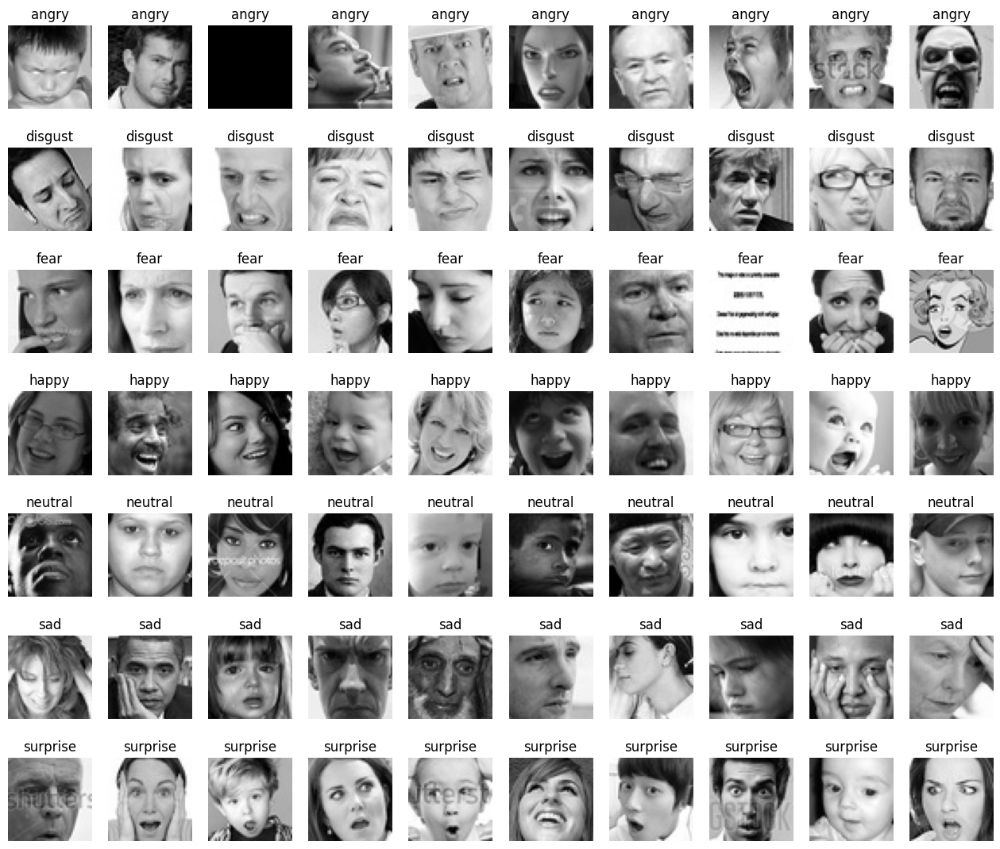

In [ ]:
fig, axs = plt.subplots(len(labels), 10, figsize=(10*1.6, len(labels)*(1.95)))

distrib ={}
indexing = {}

for i, emotion in enumerate(labels):

    distrib[emotion]=len(df[df["emotion_name"]==emotion])
    indexing[emotion]=df[df["emotion_name"]==emotion]["emotion_idx"].unique()

    emotion_df = df[df["emotion_name"]==emotion].head(10)
    j=0
    for _, val in emotion_df.iterrows():
        img_path = val["image_path"]
        img = plt.imread(img_path)

        axs[i][j].imshow(img, cmap="gray")
        axs[i][j].set_title(emotion)
        axs[i][j].axis('off')
        j+=1

### Data distribution*

In [ ]:
print("Emotion | Samples")
for key in distrib.keys():
    print(f"{key} | {distrib[key]}")

Emotion | Samples
angry | 4953
disgust | 547
fear | 5121
happy | 8990
neutral | 6214
sad | 6077
surprise | 4002


<Axes: xlabel='emotion_name', ylabel='Count'>

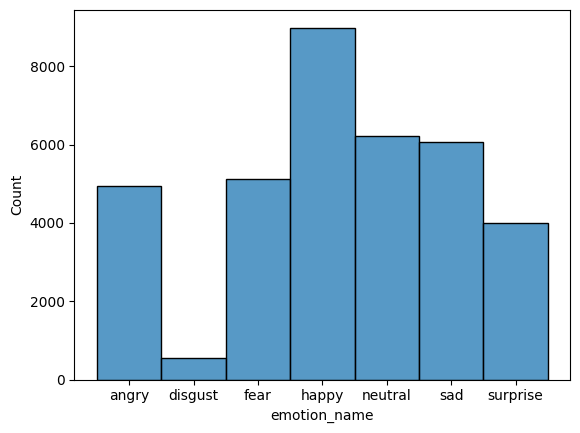

In [ ]:
sns.histplot(data=df, x="emotion_name")

In [ ]:
print("Emotion | Index number")
for key in indexing.keys():
    print(f"{key} | {indexing[key][0]}")

Emotion | Index number
angry | 0
disgust | 1
fear | 2
happy | 3
neutral | 4
sad | 5
surprise | 6


### Data Splitting*

In [ ]:
val_df, test_split_df, y_val, y_test = train_test_split(test_df, test_df["emotion_idx"], test_size=0.5, stratify=test_df["emotion_idx"])
val_df.shape, test_split_df.shape, y_val.shape, y_test.shape

((3589, 12), (3589, 12), (3589,), (3589,))

In [ ]:
plot_df = pd.concat([
    train_df,
    val_df.assign(dataset="val"),
    test_split_df.assign(dataset="test"),
], ignore_index=True)

plot_df.head()

,image_path,image,emotion_idx,emotion_name,dataset,0,1,2,3,4,5,6
0,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.19607845, 0.1254902, 0.058823533, 0.0431372...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.1137255, 0.09411766, 0.1137255, 0.043137256...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.60784316, 0.5411765, 0.38431376, 0.43921572...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.82745105, 0.8431373, 0.86274517, 0.86666673...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0


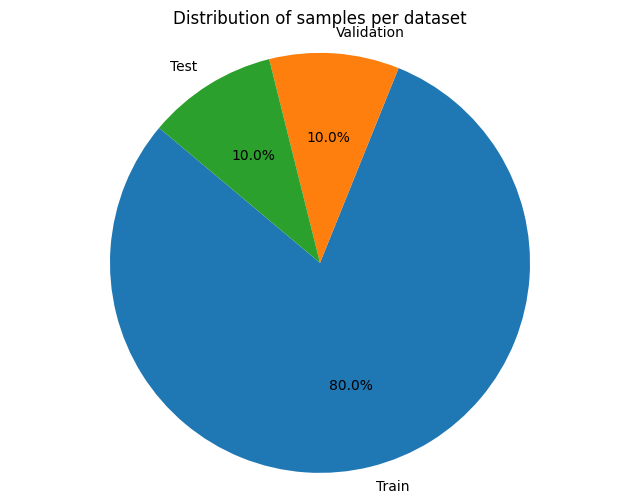

<Axes: xlabel='emotion_idx', ylabel='Count'>

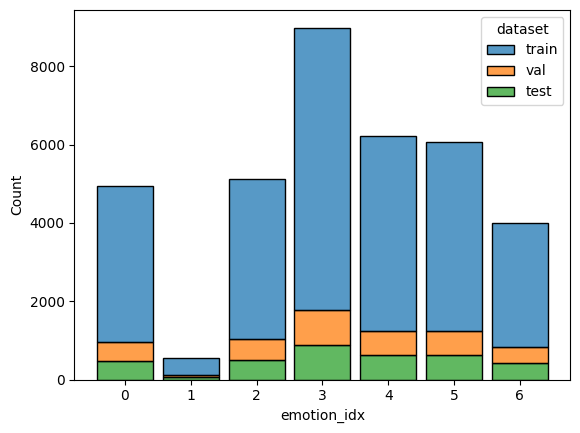

In [ ]:
labels = ["Train", "Validation", "Test"]
sizes = [len(train_df), len(val_df), len(test_split_df)]

plt.figure(figsize=(8, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of samples per dataset')
plt.axis('equal')
plt.show()

sns.histplot(
    data=plot_df,
    x="emotion_idx",
    hue="dataset",
    multiple="stack",
    discrete=True,
    stat="count",
    shrink=0.85,
    hue_order=["train", "val", "test"]
)

In [ ]:
## Ceate an interediate csv to avoid re computing of images each time
plot_df.to_pickle('partial.pkl')

### Data Cleansing

In [ ]:
complete_df = pd.read_pickle('partial.pkl')
complete_df.head()

,image_path,image,emotion_idx,emotion_name,dataset,0,1,2,3,4,5,6
0,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.19607845, 0.1254902, 0.058823533, 0.0431372...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.1137255, 0.09411766, 0.1137255, 0.043137256...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.60784316, 0.5411765, 0.38431376, 0.43921572...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.82745105, 0.8431373, 0.86274517, 0.86666673...",0,angry,train,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
np.random.seed(1)

complete_df = complete_df.iloc[np.random.permutation(len(complete_df))].reset_index(drop=True)
complete_df.head()

,image_path,image,emotion_idx,emotion_name,dataset,0,1,2,3,4,5,6
0,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.52156866, 0.4784314, 0.43137258, 0.5568628,...",4,neutral,train,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.9921569, 0.9725491, 0.9843138, 0.9921569, 0...",6,surprise,train,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.48627454, 0.4666667, 0.49411768, 0.22352943...",4,neutral,test,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.97647065, 0.9803922, 0.9843138, 0.9843138, ...",5,sad,val,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,/content/drive/MyDrive/NUMERICAL ANALYSIS FOR ...,"[0.8470589, 0.82745105, 0.9333334, 0.9843138, ...",3,happy,train,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [5]:
complete_df.dtypes

,0
image_path,object
image,object
emotion_idx,int32
emotion_name,object
dataset,object
0,float64
1,float64
2,float64
3,float64
4,float64


In [6]:
labels = {}
for l in complete_df["emotion_idx"].unique():
    labels[l]=(complete_df[complete_df["emotion_idx"]==l])["emotion_name"].unique()[0]
labels

{np.int32(4): 'neutral',
 np.int32(6): 'surprise',
 np.int32(5): 'sad',
 np.int32(3): 'happy',
 np.int32(2): 'fear',
 np.int32(0): 'angry',
 np.int32(1): 'disgust'}

In [7]:
## Function to visualize images based on some metric
def plot_analyze(data, array_param, metrics, title, param_name, limit=10):
  '''
	data: Pandas dataframe source of data
  array_param: array value to compare with the metric to calculate
  metrics: dictionary with the metrics name and function
  title: name of the analysis
  param_name: name of the param we are comparing with
  limit: number of images to show for each param
  '''
  n = len(metrics)

  df = data.copy()
  for metric in metrics:
    metric_name = metric["name"]
    df[f"img_{metric_name}"] = df["image"].apply(metric["function"])

  fig = plt.figure(constrained_layout=True, figsize=(2*limit, len(array_param) * 3 * (n+1)))
  fig.suptitle(title, fontsize=20)

  subfigs = fig.subfigures(nrows=len(array_param) * ( 1+n ), ncols=1)

  for i, param in enumerate(array_param):
    base = (n+1) * i

    principal_metric_name = metrics[0]["name"]
    filtered_df = df[df[f"img_{principal_metric_name}"] <= param]

    if (len(filtered_df["image"])<=0):
      print(f'The filter doesnt get any image for metric {metrics[0]["name"]} and value {param}')
      continue

    sf_mean = subfigs[base]
    sf_mean.suptitle(f"{param_name} ≤ {param:.2f}", fontsize=18)
    ax_mean = sf_mean.subplots(nrows=1, ncols=1)

    ax_mean.imshow((np.mean(filtered_df["image"])).reshape(48,48),cmap="gray")
    ax_mean.set_title(f"Mean image", fontsize=16)
    ax_mean.axis("off")

    for j, metric in enumerate(metrics):
      metric_name = metric["name"]
      filtered_df = filtered_df.sort_values(f"img_{metric_name}", ascending=False)

      sf_top = subfigs[base + j + 1]
      sf_top.suptitle(f"Top {limit} images (highest {metric_name} within {param_name})", fontsize=16)
      axs = sf_top.subplots(nrows=1, ncols=limit)
      for j, (_, row) in enumerate(filtered_df.head(10).iterrows()):
        axs[j].imshow(row["image"].reshape(48, 48), cmap="gray")
        axs[j].axis('off')


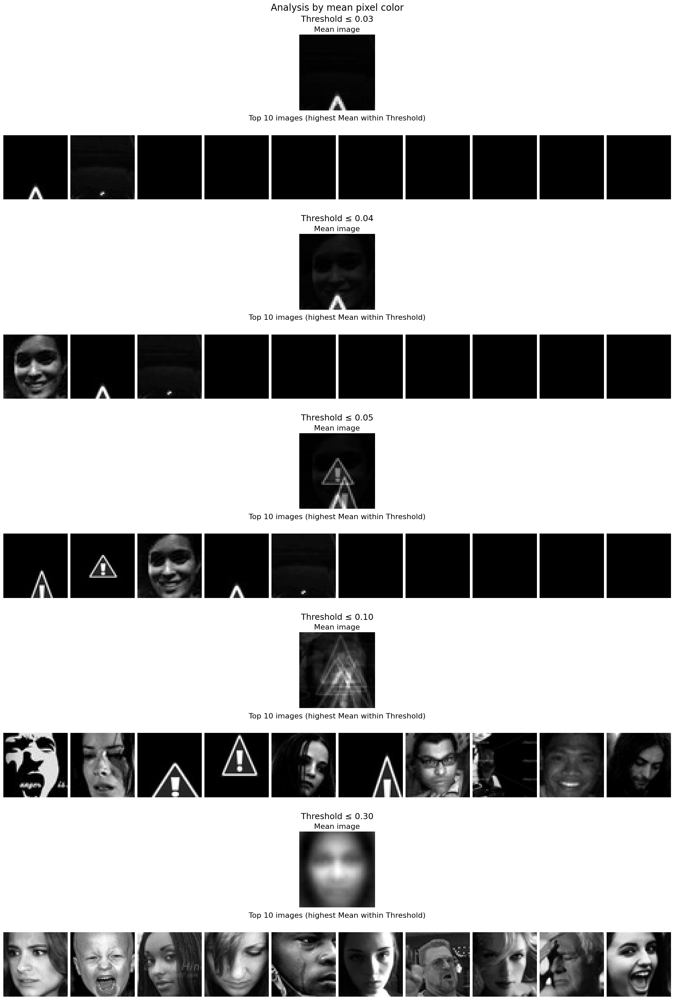

In [8]:
## Analysis by mean pixel color

thresholds = [0.025, 0.035, 0.05, 0.1, 0.3]
plot_analyze(
    complete_df,
    [x for x in thresholds],
    [{"name":"Mean", "function":(lambda img: float(np.mean(img)))}],
    "Analysis by mean pixel color", "Threshold"
)

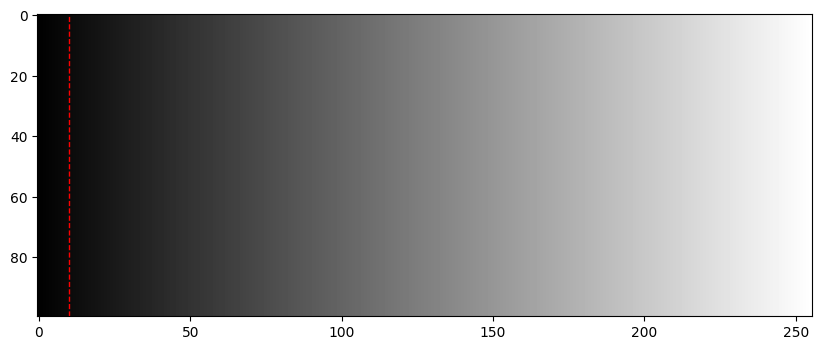

In [9]:
img = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (100, 1))

plt.figure(figsize=(10, 5))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axvline(10, color="red", linewidth=1, linestyle ="--")
plt.show()

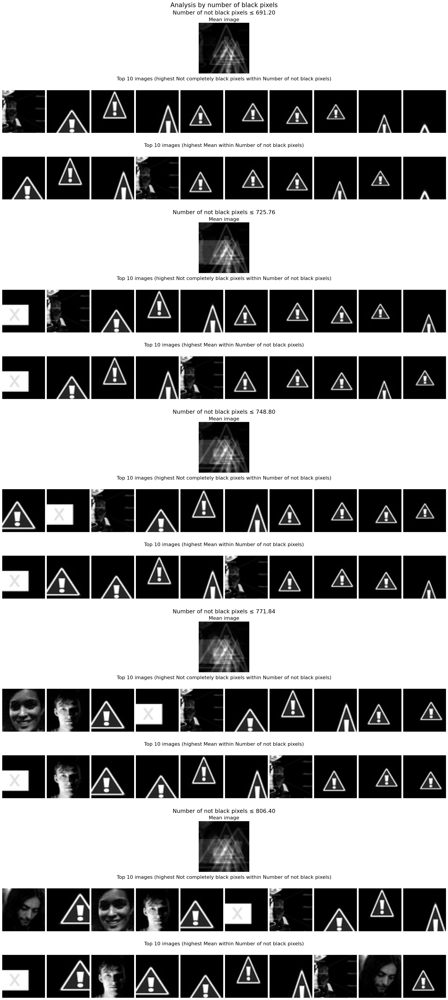

In [10]:
## Analysis by number of "black" pixels

proportions = [0.3, 0.315,0.325, 0.335, 0.35]
plot_analyze(
    complete_df,
    [x*48*48 for x in proportions],
    [{"name":"Not completely black pixels", "function":(lambda img: np.sum(img>10/255))},
     {"name":"Mean", "function":(lambda img: float(np.mean(img)))}],
    "Analysis by number of black pixels", "Number of not black pixels"
)

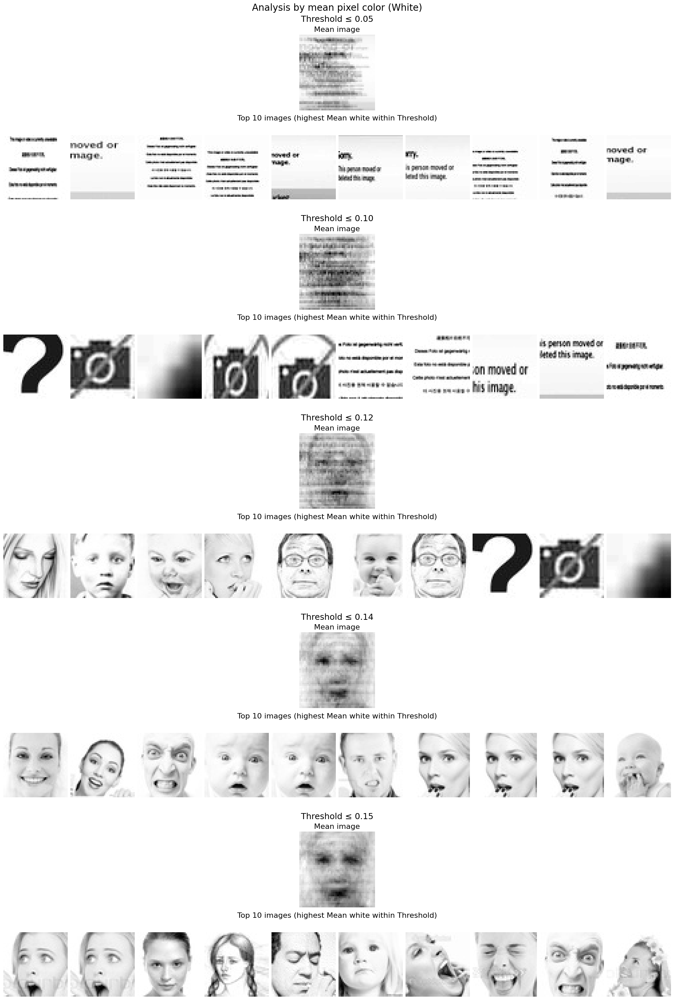

In [11]:
## Analysis by mean pixel white color

thresholds_2 = [0.05, 0.1, 0.115, 0.135 ,0.15]
plot_analyze(
    complete_df,
    [x for x in thresholds_2],
    [{"name":"Mean white", "function":(lambda img: float(np.mean(np.ones_like(img)-img)))}],
    "Analysis by mean pixel color (White)", "Threshold"
)

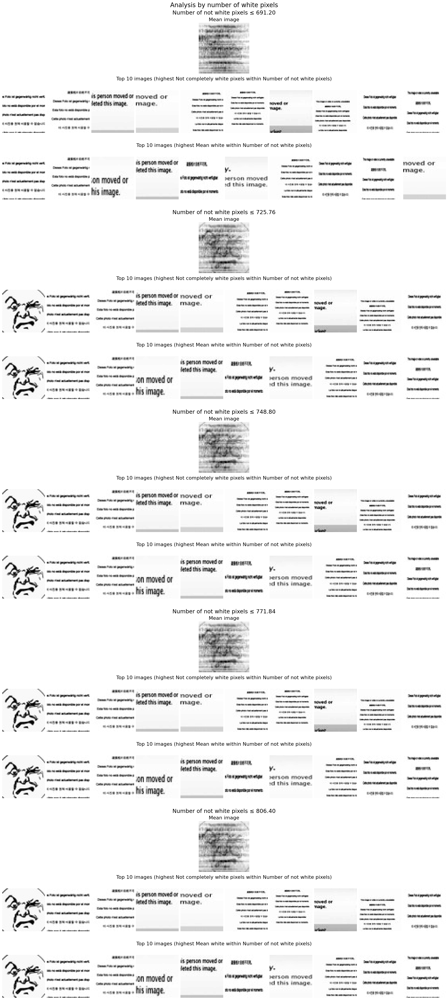

In [12]:
## Analysis by number of "white" pixels

proportions_2 = [0.2, 0.205, 0.211, 0.25, 0.3]
plot_analyze(
    complete_df,
    [x*48*48 for x in proportions],
    [{"name":"Not completely white pixels", "function":(lambda img: np.sum((np.ones_like(img)-img)>10/255))},
     {"name":"Mean white", "function":(lambda img: float(np.mean(np.ones_like(img)-img)))}],
    "Analysis by number of white pixels", "Number of not white pixels"
)

In [13]:
auxiliar_df = complete_df.copy()

## Computation of metrics evaluated
auxiliar_df[f"img_mean"] = auxiliar_df["image"].apply(lambda img: float(np.mean(img)))
auxiliar_df[f"img_no_black"] = auxiliar_df["image"].apply(lambda img: np.sum(img>10/255))
auxiliar_df[f"img_mean_white"] = auxiliar_df["image"].apply(lambda img: float(np.mean(np.ones_like(img)-img)))
auxiliar_df[f"img_no_white"] = auxiliar_df["image"].apply(lambda img: np.sum((np.ones_like(img)-img)>10/255))

## Get cleaned dataset
cleanse_df = auxiliar_df[
    (auxiliar_df["img_no_black"] > 0.325 * 48 * 48)
    & (auxiliar_df["img_mean"] > 0.025)
    & (auxiliar_df["img_no_white"] > 0.2 * 48 * 48)
    & (auxiliar_df["img_mean_white"] > 0.1)
]

cleanse_df.shape, complete_df.shape

((35851, 16), (35904, 12))

In [14]:
cleanse_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 35851 entries, 0 to 35903
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image_path      35851 non-null  object 
 1   image           35851 non-null  object 
 2   emotion_idx     35851 non-null  int32  
 3   emotion_name    35851 non-null  object 
 4   dataset         35851 non-null  object 
 5   0               35851 non-null  float64
 6   1               35851 non-null  float64
 7   2               35851 non-null  float64
 8   3               35851 non-null  float64
 9   4               35851 non-null  float64
 10  5               35851 non-null  float64
 11  6               35851 non-null  float64
 12  img_mean        35851 non-null  float64
 13  img_no_black    35851 non-null  int64  
 14  img_mean_white  35851 non-null  float64
 15  img_no_white    35851 non-null  int64  
dtypes: float64(9), int32(1), int64(2), object(4)
memory usage: 4.5+ MB


In [15]:
removed_df = auxiliar_df[
    (auxiliar_df["img_no_black"] <= 0.325 * 48 * 48)
    | (auxiliar_df["img_mean"] <= 0.025)
    | (auxiliar_df["img_no_white"] <= 0.2 * 48 * 48)
    | (auxiliar_df["img_mean_white"] <= 0.1)
]
len(removed_df)

53

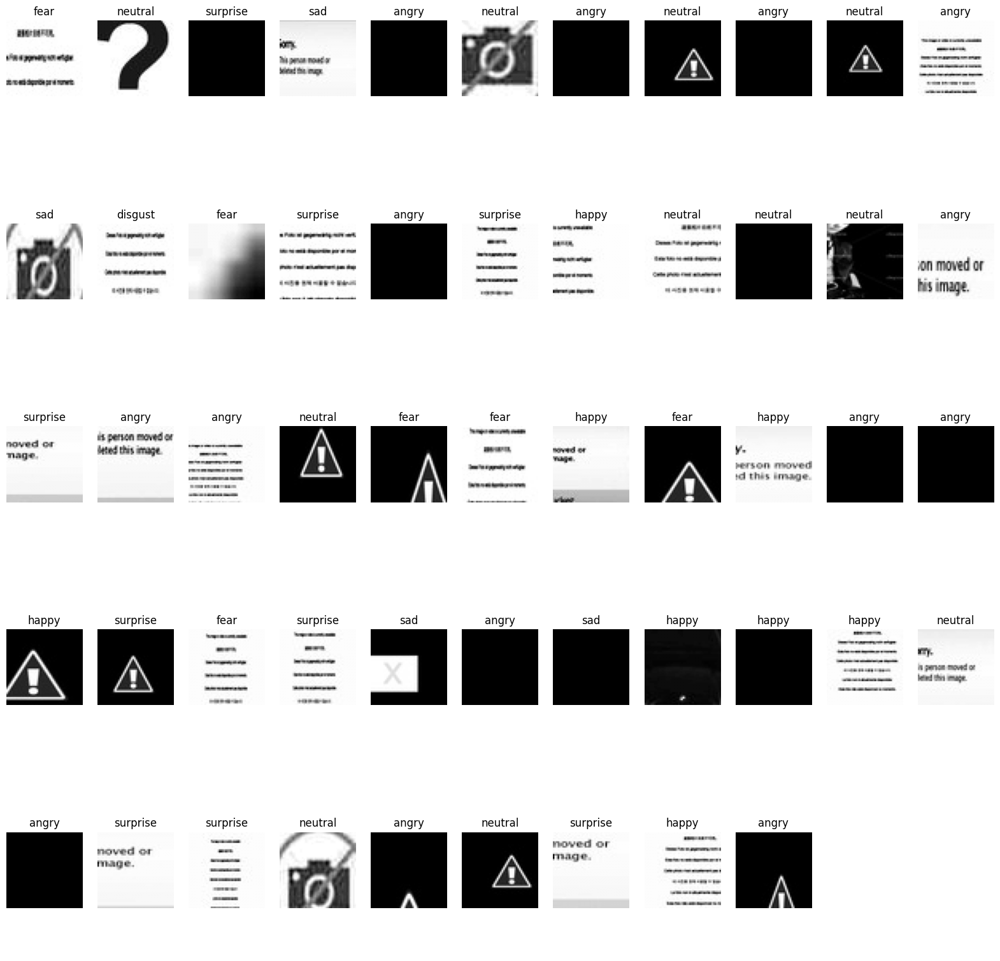

In [16]:
fig, axs = plt.subplots(5, 11, figsize=(20, 20))
axs = axs.reshape(-1)
for ax in axs:
  ax.axis('off')
for i,(_, img) in enumerate(removed_df.iterrows()):
  axs[i].imshow(img['image'].reshape(48,48), cmap='gray')
  axs[i].set_title(img['emotion_name'])
  axs[i].axis('off')

## Data sets and variables definition

In [17]:
train_df = cleanse_df[cleanse_df["dataset"]=="train"]
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 28683 entries, 0 to 35902
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image_path      28683 non-null  object 
 1   image           28683 non-null  object 
 2   emotion_idx     28683 non-null  int32  
 3   emotion_name    28683 non-null  object 
 4   dataset         28683 non-null  object 
 5   0               28683 non-null  float64
 6   1               28683 non-null  float64
 7   2               28683 non-null  float64
 8   3               28683 non-null  float64
 9   4               28683 non-null  float64
 10  5               28683 non-null  float64
 11  6               28683 non-null  float64
 12  img_mean        28683 non-null  float64
 13  img_no_black    28683 non-null  int64  
 14  img_mean_white  28683 non-null  float64
 15  img_no_white    28683 non-null  int64  
dtypes: float64(9), int32(1), int64(2), object(4)
memory usage: 3.6+ MB


<Axes: xlabel='emotion_name', ylabel='Count'>

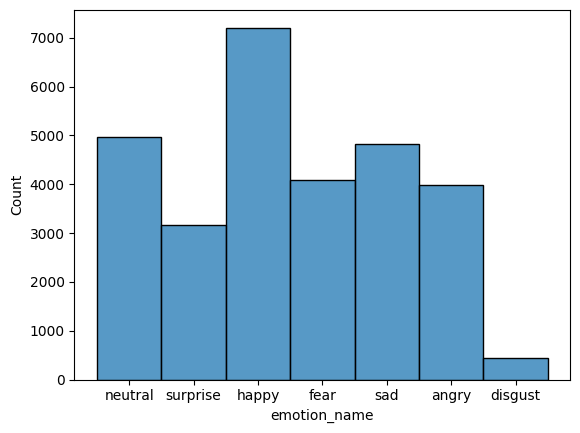

In [18]:
sns.histplot(data=train_df, x="emotion_name")

In [19]:
val_df = cleanse_df[cleanse_df["dataset"]=="val"]
val_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3583 entries, 3 to 35894
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image_path      3583 non-null   object 
 1   image           3583 non-null   object 
 2   emotion_idx     3583 non-null   int32  
 3   emotion_name    3583 non-null   object 
 4   dataset         3583 non-null   object 
 5   0               3583 non-null   float64
 6   1               3583 non-null   float64
 7   2               3583 non-null   float64
 8   3               3583 non-null   float64
 9   4               3583 non-null   float64
 10  5               3583 non-null   float64
 11  6               3583 non-null   float64
 12  img_mean        3583 non-null   float64
 13  img_no_black    3583 non-null   int64  
 14  img_mean_white  3583 non-null   float64
 15  img_no_white    3583 non-null   int64  
dtypes: float64(9), int32(1), int64(2), object(4)
memory usage: 461.9+ KB


<Axes: xlabel='emotion_name', ylabel='Count'>

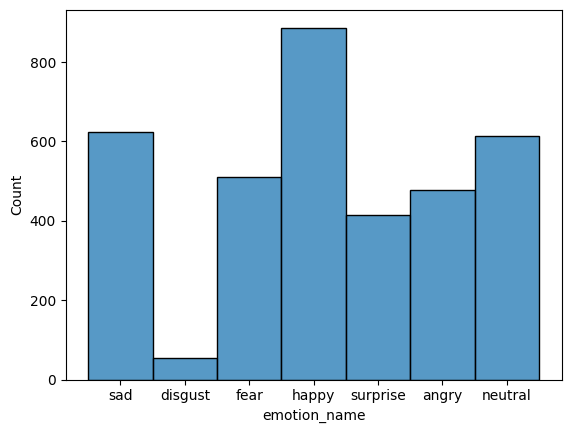

In [20]:
sns.histplot(data=val_df, x="emotion_name")

In [21]:
test_df = cleanse_df[cleanse_df["dataset"]=="test"]
test_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3585 entries, 2 to 35903
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image_path      3585 non-null   object 
 1   image           3585 non-null   object 
 2   emotion_idx     3585 non-null   int32  
 3   emotion_name    3585 non-null   object 
 4   dataset         3585 non-null   object 
 5   0               3585 non-null   float64
 6   1               3585 non-null   float64
 7   2               3585 non-null   float64
 8   3               3585 non-null   float64
 9   4               3585 non-null   float64
 10  5               3585 non-null   float64
 11  6               3585 non-null   float64
 12  img_mean        3585 non-null   float64
 13  img_no_black    3585 non-null   int64  
 14  img_mean_white  3585 non-null   float64
 15  img_no_white    3585 non-null   int64  
dtypes: float64(9), int32(1), int64(2), object(4)
memory usage: 462.1+ KB


<Axes: xlabel='emotion_name', ylabel='Count'>

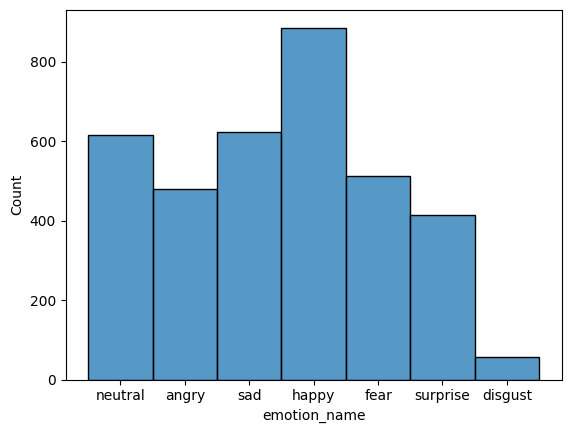

In [22]:
sns.histplot(data=test_df, x="emotion_name")

In [23]:
labels

{np.int32(4): 'neutral',
 np.int32(6): 'surprise',
 np.int32(5): 'sad',
 np.int32(3): 'happy',
 np.int32(2): 'fear',
 np.int32(0): 'angry',
 np.int32(1): 'disgust'}

In [24]:
X_train = np.stack(train_df["image"].to_numpy())
y_train = np.array(train_df["emotion_idx"])
y_train_one_hot = np.array(train_df[range(7)]).astype(int)

X_train, y_train, y_train_one_hot = shuffle(X_train, y_train, y_train_one_hot, random_state=42)

X_val =  np.stack(val_df["image"].to_numpy())
y_val = np.array(val_df["emotion_idx"])
y_val_one_hot = np.array(val_df[range(7)]).astype(int)

X_test =  np.stack(test_df["image"].to_numpy())
y_test = np.array(test_df["emotion_idx"])
y_test_one_hot = np.array(test_df[range(7)]).astype(int)

X_train_model = X_train.reshape(-1,48,48,1)
X_val_model = X_val.reshape(-1,48,48,1)
X_test_model = X_test.reshape(-1,48,48,1)

X_train.shape, y_train.shape, y_train_one_hot.shape, X_val.shape, y_val.shape, y_val_one_hot.shape, X_test.shape, y_test.shape, y_test_one_hot.shape

((28683, 2304),
 (28683,),
 (28683, 7),
 (3583, 2304),
 (3583,),
 (3583, 7),
 (3585, 2304),
 (3585,),
 (3585, 7))

## PCA

In [ ]:
X_train_mean = np.mean(X_train, axis = 0)
X_train_mean.shape

(2304,)

(np.float64(-0.5), np.float64(47.5), np.float64(47.5), np.float64(-0.5))

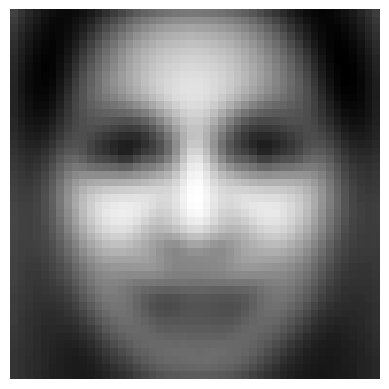

In [ ]:
plt.imshow(X_train_mean.reshape((48,48)), cmap='gray')
plt.axis('off')

In [ ]:
X_bar = X_train - X_train_mean

## Transpose it to have principal components as columns of U
X_bar = X_bar.T
X_bar.shape, X_train.shape, X_train_mean.shape

((2304, 28683), (28683, 2304), (2304,))

In [ ]:
U, s, Vt = np.linalg.svd(X_bar, full_matrices=False)
U.shape, s.shape, Vt.shape

((2304, 2304), (2304,), (2304, 28683))

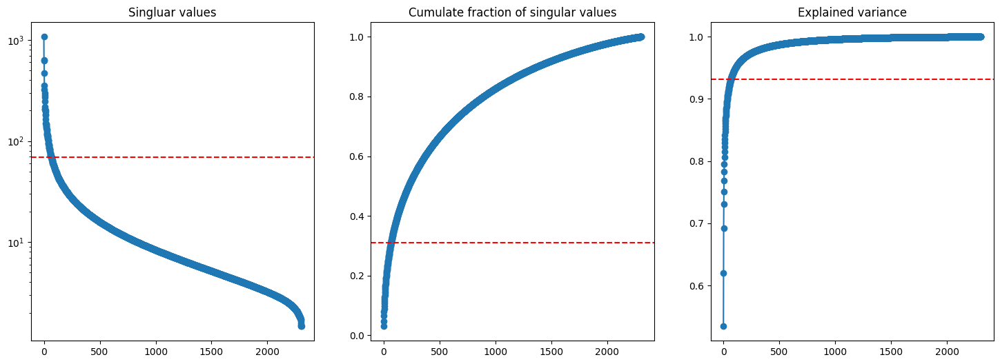

In [ ]:
k = 67
cum_frac = np.cumsum(s) / np.sum(s)
expl_var = np.sqrt(np.cumsum(s**2) / np.sum(s**2))

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))
axes[0].semilogy(s, "o-")
axes[0].set_title("Singluar values")
axes[0].axhline(s[k-1], linestyle="--", c='red')

axes[1].plot(cum_frac, "o-")
axes[1].set_title("Cumulate fraction of singular values")
axes[1].axhline(cum_frac[k-1], linestyle="--", c='red')

axes[2].plot(expl_var, "o-")
axes[2].set_title("Explained variance")
axes[2].axhline(expl_var[k-1], linestyle="--", c='red')

In [ ]:
print(f'First {k}th components')
print(f'Percentage of information: {cum_frac[k-1]}')
print(f'Percentage of the variance: {expl_var[k-1]}')

First 67th components
Percentage of information: 0.31038978695869446
Percentage of the variance: 0.9314526915550232


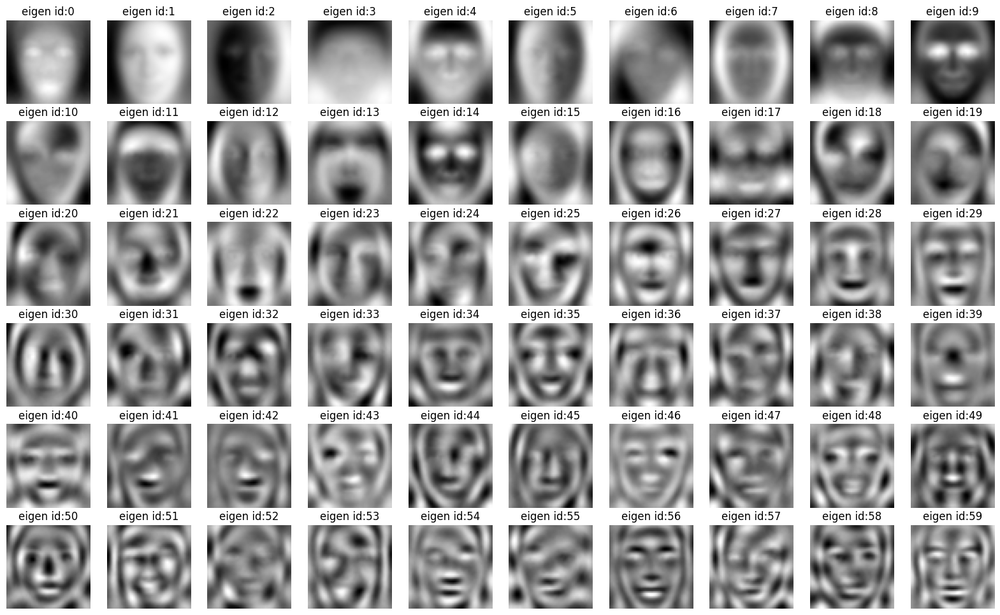

In [ ]:
fig, axs = plt.subplots(6, 10, figsize=(20, 12))
axs = axs.reshape((-1,))

for i in range(60):
    axs[i].imshow(U[:,i].reshape(48,48), cmap="gray")
    axs[i].set_title(f'eigen id:{i}')
    axs[i].axis('off')

In [ ]:
print(f'n_samples: {X_train.shape[0]}')
print(f'n_features: {X_train.shape[1]}')

n_samples: 28683
n_features: 2304


In [ ]:
pca = PCA(n_components=70, svd_solver='full', random_state=1)
X_pca = pca.fit(X_train)

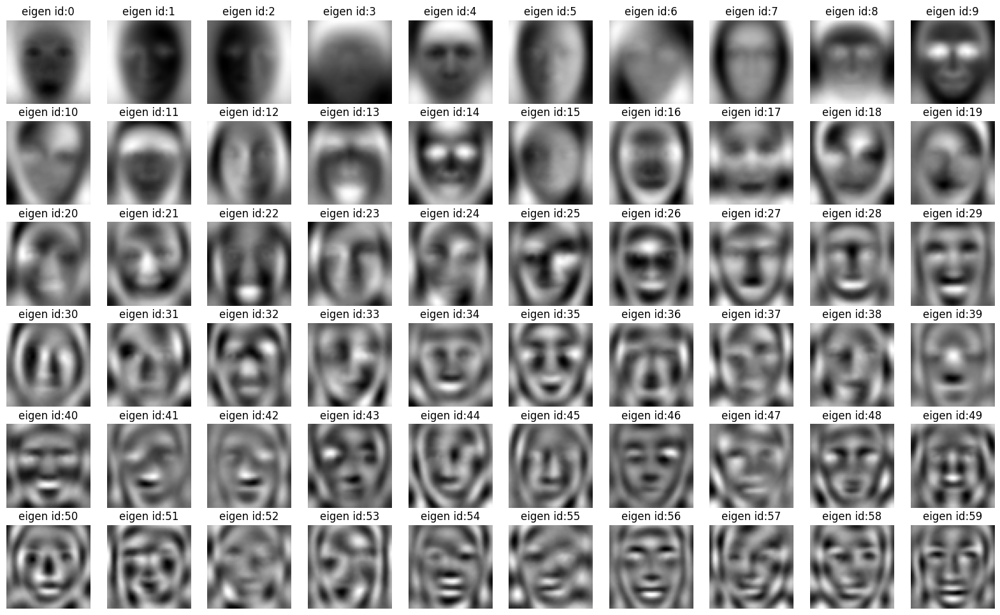

In [ ]:
fig, axs = plt.subplots(6, 10, figsize=(20, 12))
axs = axs.reshape((-1,))

for i in range(60):
    axs[i].imshow(X_pca.components_[i].reshape(48,48), cmap="gray")
    axs[i].set_title(f'eigen id:{i}')
    axs[i].axis('off')

In [ ]:
Phi = U.T @ X_bar
Phi.shape

(2304, 28683)

In [ ]:
Phi_val = U.T @ (X_val-X_train_mean).T
Phi_test = U.T @ (X_test-X_train_mean).T
Phi_val.shape, Phi_test.shape

((2304, 3583), (2304, 3585))

In [ ]:
Phi_sklearn = pca.transform(X_train)
Phi_sklearn.shape

(28683, 70)

In [ ]:
Phi_val_sklearn = pca.transform(X_val)
Phi_test_sklearn = pca.transform(X_test)
Phi_val_sklearn.shape, Phi_test_sklearn.shape

((3583, 70), (3585, 70))

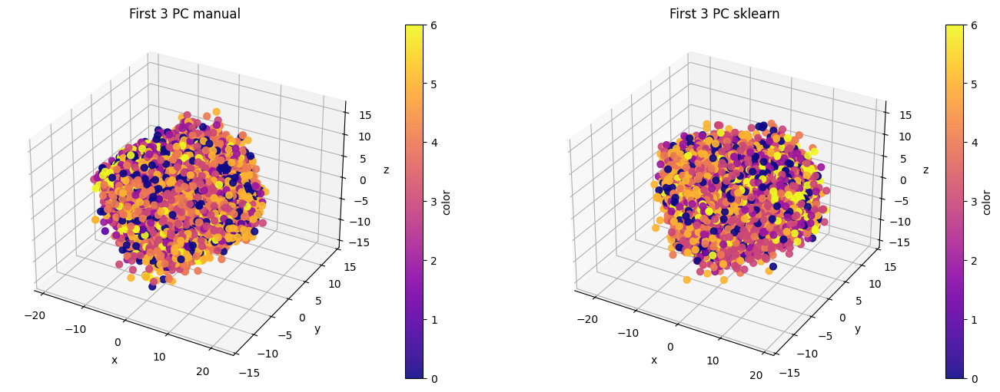

In [ ]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, 5),
    subplot_kw={"projection": "3d"},
    constrained_layout=True
)

sc = ax1.scatter(
    Phi[0], Phi[1], Phi[2],
    c=y_train, cmap="plasma", s=40, alpha=0.9
)

ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_zlabel("z")
ax1.set_title('First 3 PC manual')

cb = fig.colorbar(sc, ax=ax1, pad=0.1)
cb.set_label("color")


sc2 = ax2.scatter(
    Phi_sklearn[:, 0], Phi_sklearn[:, 1], Phi_sklearn[:, 2],
    c=y_train, cmap="plasma", s=40, alpha=0.9
)

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")
ax2.set_title('First 3 PC sklearn')

cb2 = fig.colorbar(sc2, ax=ax2, pad=0.1)
cb2.set_label("color")

plt.show()


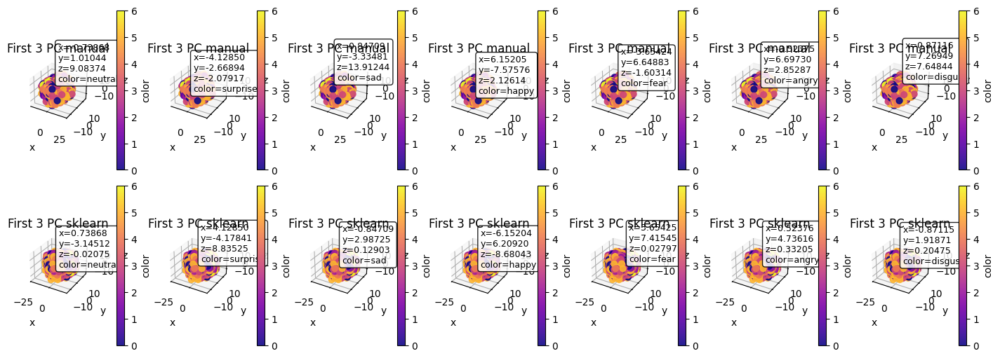

In [ ]:
fig, axs = plt.subplots(
    2, 7, figsize=(14, 5),
    subplot_kw={"projection": "3d"},
    constrained_layout=True
)

for i ,label in enumerate(labels.keys()):
    sc = axs[0][i].scatter(
        Phi[0], Phi[1], Phi[2],
        c=y_train, cmap="plasma", s=40, alpha=0.9
    )

    mask = (y_train ==label)
    value = Phi[:, mask][0]
    axs[0][i].text(
        value[0], value[1], value[2],
        f"x={value[0]:.5f}\ny={value[1]:.5f}\nz={value[2]:.5f}\ncolor={labels[label]}",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85)
    )

    axs[0][i].set_xlabel("x")
    axs[0][i].set_ylabel("y")
    axs[0][i].set_zlabel("z")
    axs[0][i].set_title('First 3 PC manual')

    cb1 = fig.colorbar(sc, ax=axs[0][i], pad=0.1)
    cb1.set_label("color")

for i ,label in enumerate(labels.keys()):
    sc = axs[1][i].scatter(
        Phi_sklearn[:, 0], Phi_sklearn[:, 1], Phi_sklearn[:, 2],
        c=y_train, cmap="plasma", s=40, alpha=0.9
    )

    mask = (y_train ==label)
    value = Phi_sklearn[mask][0]

    axs[1][i].text(
        value[0], value[1], value[2],
        f"x={value[0]:.5f}\ny={value[1]:.5f}\nz={value[2]:.5f}\ncolor={labels[label]}",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85)
    )

    axs[1][i].set_xlabel("x")
    axs[1][i].set_ylabel("y")
    axs[1][i].set_zlabel("z")
    axs[1][i].set_title('First 3 PC sklearn')

    cb2 = fig.colorbar(sc, ax=axs[1][i], pad=0.1)
    cb2.set_label("color")

## Model 1 (SVM's)

### Data formatting (67 PCA)

In [ ]:
X_SVM_train = Phi[:67].T
X_SVM_train_sklearn = Phi_sklearn[:, :67]
X_SVM_train.shape, X_SVM_train_sklearn.shape, y_train.shape, X_SVM_train.max(), X_SVM_train.min()

((28683, 67),
 (28683, 67),
 (28683,),
 np.float32(22.071177),
 np.float32(-19.150242))

In [ ]:
X_SVM_mean = np.mean(X_SVM_train, axis=0)
X_SVM_std = np.std(X_SVM_train, axis=0)
X_SVM_train = (X_SVM_train - X_SVM_mean) / X_SVM_std
X_SVM_train.shape, X_SVM_train.max(), X_SVM_train.min()

((28683, 67), np.float32(9.578803), np.float32(-8.478928))

In [ ]:
X_SVM_sklearn_mean = np.mean(X_SVM_train_sklearn, axis=0)
X_SVM_sklearn_std = np.std(X_SVM_train_sklearn, axis=0)
X_SVM_train_sklearn = (X_SVM_train_sklearn - X_SVM_sklearn_mean) / X_SVM_sklearn_std
X_SVM_train_sklearn.shape, X_SVM_train_sklearn.max(), X_SVM_train_sklearn.min()

((28683, 67), np.float32(9.578836), np.float32(-6.80751))

In [ ]:
X_SVM_val = Phi_val[:67].T
X_SVM_val = (X_SVM_val - X_SVM_mean) / X_SVM_std
X_SVM_val.shape, X_SVM_val.max(), X_SVM_val.min()

((3583, 67), np.float32(6.370822), np.float32(-6.1389604))

In [ ]:
X_SVM_val_sklearn = Phi_val_sklearn[:, :67]
X_SVM_val_sklearn = (X_SVM_val_sklearn - X_SVM_sklearn_mean) / X_SVM_sklearn_std
X_SVM_val_sklearn.shape, X_SVM_val_sklearn.max(), X_SVM_val_sklearn.min()

((3583, 67), np.float32(5.768999), np.float32(-6.37083))

In [ ]:
X_SVM_test = Phi_test[:67].T
X_SVM_test = (X_SVM_test - X_SVM_mean) / X_SVM_std
X_SVM_test.shape, X_SVM_test.max(), X_SVM_test.min()

((3585, 67), np.float32(5.5733533), np.float32(-5.9162507))

### SVC model*

In [ ]:
model_1 = svm.SVC(random_state=1)
model_1

SVC(random_state=1)

In [ ]:
model_1.fit(X_SVM_train, y_train.astype(float))
model_1

SVC(random_state=1)

In [ ]:
model_11 = svm.SVC(random_state=1)
model_11

SVC(random_state=1)

In [ ]:
model_11.fit(X_SVM_train_sklearn, y_train)
model_11

SVC(random_state=1)

In [ ]:
y_val_pred = model_1.predict(X_SVM_val)
y_val_pred.shape

(3583,)

In [ ]:
np.sum(y_val_pred==3), len(y_val_pred)

(np.int64(1286), 3583)

In [ ]:
y_val_pred_sklearn = model_11.predict(X_SVM_val_sklearn)
y_val_pred_sklearn.shape

(3583,)

In [ ]:
report = metrics.classification_report(
    y_val, y_val_pred,
    labels=[int(l) for l in labels.keys()],
    output_dict=True,
    zero_division=0
)

df = pd.DataFrame(report).T
df = df[["precision","recall","f1-score","support"]]
print(df.to_string())

              precision    recall  f1-score      support
0              0.409677  0.266247  0.322745   477.000000
1              1.000000  0.127273  0.225806    55.000000
2              0.396396  0.258317  0.312796   511.000000
3              0.524883  0.760992  0.621261   887.000000
4              0.438914  0.473171  0.455399   615.000000
5              0.402439  0.423756  0.412823   623.000000
6              0.728659  0.575904  0.643338   415.000000
accuracy       0.484231  0.484231  0.484231     0.484231
macro avg      0.557281  0.412237  0.427738  3583.000000
weighted avg   0.486071  0.484231  0.469302  3583.000000


In [ ]:
report = metrics.classification_report(
    y_val, y_val_pred_sklearn,
    labels=[int(l) for l in labels.keys()],
    output_dict=True,
    zero_division=0
)

df = pd.DataFrame(report).T
df = df[["precision","recall","f1-score","support"]]
print(df.to_string())

              precision    recall  f1-score      support
0              0.409677  0.266247  0.322745   477.000000
1              1.000000  0.127273  0.225806    55.000000
2              0.396396  0.258317  0.312796   511.000000
3              0.525292  0.760992  0.621547   887.000000
4              0.438253  0.473171  0.455043   615.000000
5              0.402439  0.423756  0.412823   623.000000
6              0.728659  0.575904  0.643338   415.000000
accuracy       0.484231  0.484231  0.484231     0.484231
macro avg      0.557245  0.412237  0.427728  3583.000000
weighted avg   0.486058  0.484231  0.469312  3583.000000


### Model tunning*

#### Kernel*

In [ ]:
kernel = ['poly-3', 'poly-10', 'poly-15', 'rbf', 'sigmoid']

hist = list()

for i, k in enumerate(tqdm(kernel, total=len(kernel), desc="Testing kernel")):
    ker = k.split('-')
    deg=3
    if len(ker)>1:
      deg = int(ker[1])
    model = svm.SVC(kernel = ker[0], random_state=1, degree=deg)
    model.fit(X_SVM_train, y_train)
    y_val_pred = model.predict(X_SVM_val)
    report = metrics.classification_report(
        y_val, y_val_pred,
        labels=[int(l) for l in labels.keys()],
        output_dict=True,
        zero_division=0
    )
    df = pd.DataFrame(report).T
    df = df[["precision","recall","f1-score","support"]]
    hist.append(df)

Testing kernel: 100%|██████████| 5/5 [11:38<00:00, 139.62s/it]


Text(0.5, 1.0, 'F1-Score per class by kernel')

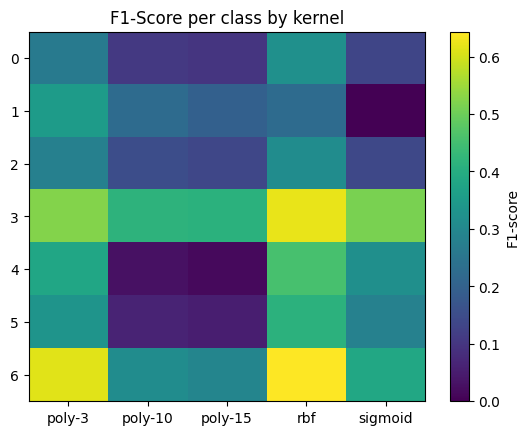

In [ ]:
label_ids = [int(l) for l in labels.keys()]

f1_plot = pd.DataFrame(
    {k : np.array(hist[i]["f1-score"])[:-3] for i, k in enumerate(kernel)}
)

plt.imshow(f1_plot.values, aspect="auto")
plt.yticks(range(len(label_ids)), label_ids)
plt.xticks(range(len(kernel)), kernel)
plt.colorbar(label="F1-score")
plt.title("F1-Score per class by kernel")

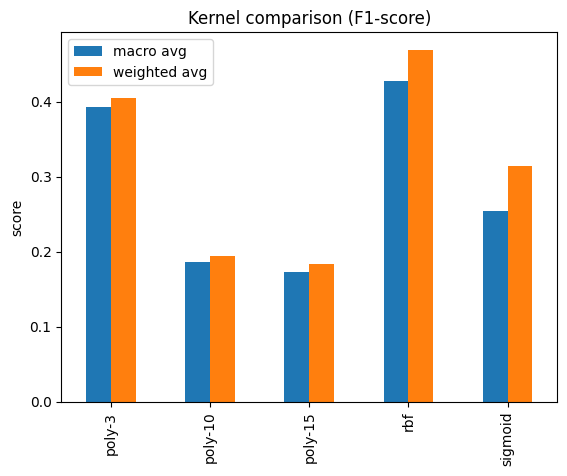

In [ ]:
f1_bar_plot = pd.DataFrame(
    {k : hist[i]["f1-score"].loc[["macro avg", "weighted avg"]] for i, k in enumerate(kernel)}
).T

ax = f1_bar_plot[["macro avg", "weighted avg"]].plot(kind="bar")
ax.set_ylabel("score")
ax.set_title("Kernel comparison (F1-score)")
plt.show()

In [ ]:
kernel = ['poly', 'rbf', 'sigmoid']

hist = list()

for i, k in enumerate(tqdm(kernel, total=len(kernel), desc="Testing kernel")):
    model = svm.SVC(kernel = k, random_state=1)
    model.fit(X_SVM, y_train)
    y_val_pred = model.predict(Phi_val[:67].T)
    report = metrics.classification_report(
        y_val, y_val_pred,
        labels=[int(l) for l in labels.keys()],
        output_dict=True,
        zero_division=0
    )
    df = pd.DataFrame(report).T
    df = df[["precision","recall","f1-score","support"]]
    hist.append(df)

Testing kernel: 100%|██████████| 3/3 [03:57<00:00, 79.07s/it]


Text(0.5, 1.0, 'F1-Score per class by kernel')

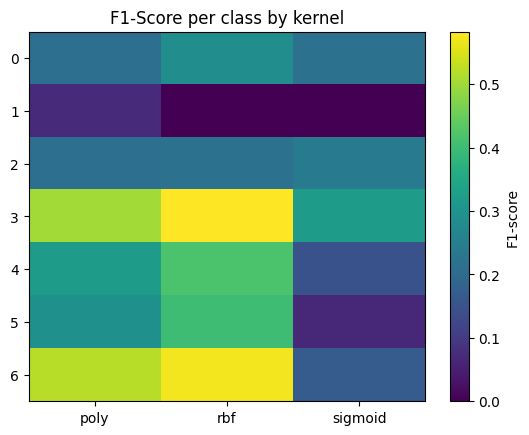

In [ ]:
label_ids = [int(l) for l in labels.keys()]

f1_plot = pd.DataFrame(
    {k : np.array(hist[i]["f1-score"])[:-3] for i, k in enumerate(kernel)}
)

plt.imshow(f1_plot.values, aspect="auto")
plt.yticks(range(len(label_ids)), label_ids)
plt.xticks(range(len(kernel)), kernel)
plt.colorbar(label="F1-score")
plt.title("F1-Score per class by kernel")

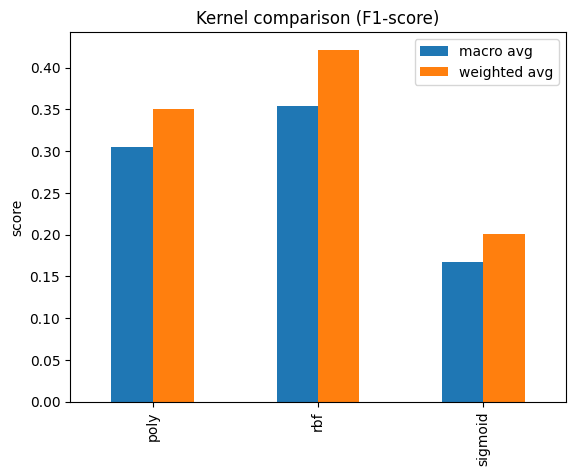

In [ ]:
f1_bar_plot = pd.DataFrame(
    {k : hist[i]["f1-score"].loc[["macro avg", "weighted avg"]] for i, k in enumerate(kernel)}
).T

ax = f1_bar_plot[["macro avg", "weighted avg"]].plot(kind="bar")
ax.set_ylabel("score")
ax.set_title("Kernel comparison (F1-score)")
plt.show()

#### Regularization parameter*

In [ ]:
reg_param = np.logspace(-4, 4, 11)

hist_reg = list()

for i, reg in enumerate(tqdm(reg_param, total=len(reg_param), desc="Testing reg param")):
    model = svm.SVC(C= reg,kernel = 'rbf', random_state=1)
    model.fit(X_SVM_train, y_train)
    y_val_pred = model.predict(X_SVM_val)
    report = metrics.classification_report(
        y_val, y_val_pred,
        labels=[int(l) for l in labels.keys()],
        output_dict=True,
        zero_division=0
    )
    df = pd.DataFrame(report).T
    df = df[["precision","recall","f1-score","support"]]
    hist_reg.append(df)

Testing reg param: 100%|██████████| 11/11 [30:10<00:00, 164.55s/it]


Text(0.5, 1.0, 'F1-Score per class by regularization parameter')

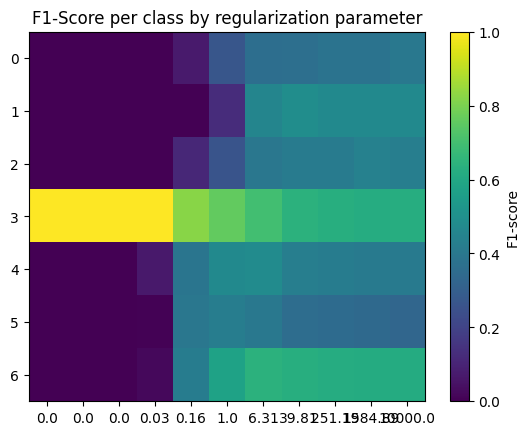

In [ ]:
label_ids = [int(l) for l in labels.keys()]

f1_plot = pd.DataFrame(
    {k : np.array(hist_reg[i]["recall"])[:-3] for i, k in enumerate(reg_param)}
)

plt.imshow(f1_plot.values, aspect="auto")
plt.yticks(range(len(label_ids)), label_ids)
plt.xticks(range(len(reg_param)), [round(x,2) for x in reg_param])
plt.colorbar(label="F1-score")
plt.title("F1-Score per class by regularization parameter")

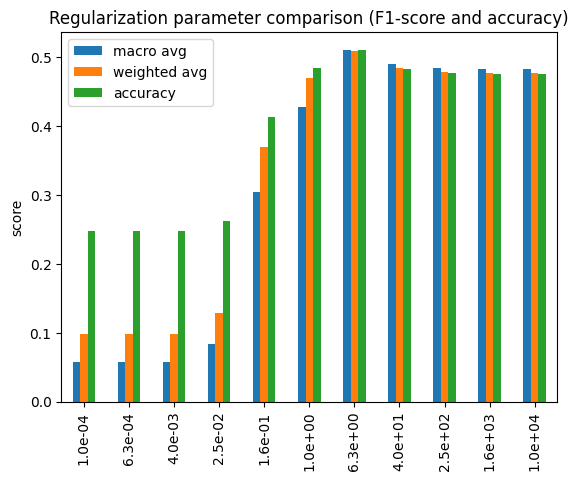

In [ ]:
f1_bar_plot = pd.DataFrame(
    {p : hist_reg[i]["f1-score"].loc[["macro avg", "weighted avg", "accuracy"]] for i, p in enumerate(reg_param)}
).T

f1_bar_plot.index = [f"{g:.1e}" for g in f1_bar_plot.index]

ax = f1_bar_plot[["macro avg", "weighted avg", "accuracy"]].plot(kind="bar")
ax.set_ylabel("score")
ax.set_title("Regularization parameter comparison (F1-score and accuracy)")
plt.show()

#### Gamma parameter*

In [ ]:
gamma0 = 1.0 / (X_SVM_train.shape[1] * X_SVM_train.var())
gammas = gamma0 * np.logspace(-3, 3, 13)

hist_gam = list()

for i, g in enumerate(tqdm(gammas, total=len(gammas), desc="Testing gamma param")):
    model = svm.SVC(C= reg_param[6],kernel = 'rbf', random_state=1, gamma=g)
    model.fit(X_SVM_train, y_train)
    y_val_pred = model.predict(X_SVM_val)
    report = metrics.classification_report(
        y_val, y_val_pred,
        labels=[int(l) for l in labels.keys()],
        output_dict=True,
        zero_division=0
    )
    df = pd.DataFrame(report).T
    df = df[["precision","recall","f1-score","support"]]
    hist_gam.append(df)

Testing gamma param: 100%|██████████| 13/13 [57:39<00:00, 266.09s/it]


Text(0.5, 1.0, 'F1-Score per class by gamma')

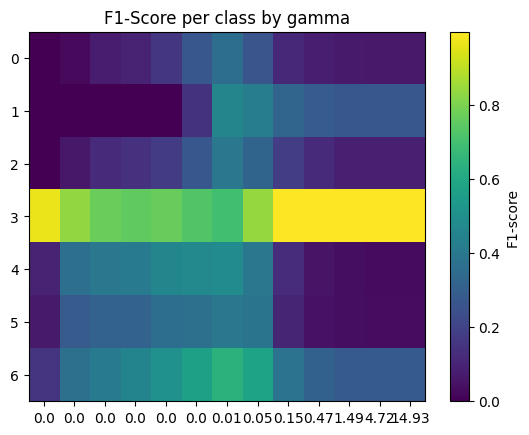

In [ ]:
label_ids = [int(l) for l in labels.keys()]

f1_plot = pd.DataFrame(
    {k : np.array(hist_gam[i]["recall"])[:-3] for i, k in enumerate(gammas)}
)

plt.imshow(f1_plot.values, aspect="auto")
plt.yticks(range(len(label_ids)), label_ids)
plt.xticks(range(len(gammas)), [round(x,2) for x in gammas])
plt.colorbar(label="F1-score")
plt.title("F1-Score per class by gamma")

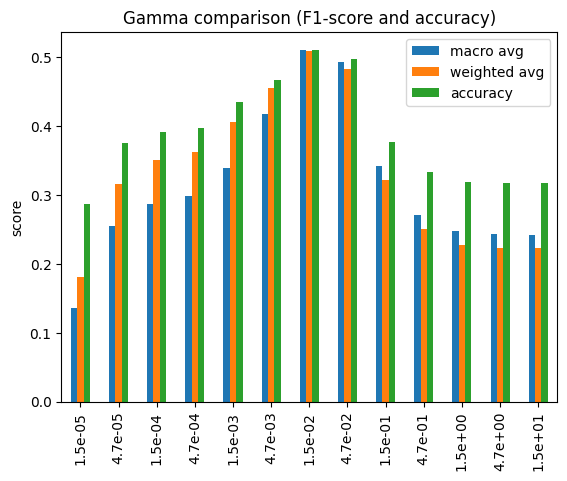

In [ ]:
f1_bar_plot = pd.DataFrame(
    {p : hist_gam[i]["f1-score"].loc[["macro avg", "weighted avg", "accuracy"]] for i, p in enumerate(gammas)}
).T

f1_bar_plot.index = [f"{g:.1e}" for g in f1_bar_plot.index]

ax = f1_bar_plot[["macro avg", "weighted avg", "accuracy"]].plot(kind="bar")
ax.set_ylabel("score")
ax.set_title("Gamma comparison (F1-score and accuracy)")
plt.show()

In [ ]:
print('Optimal parameters')
print(f'\t Kernel:{kernel[1]}')
print(f'\t Regularization parameter:{reg_param[6]}')
print(f'\t Gamma parameter:{gammas[6]}')

Optimal parameters
	 Kernel:poly-10
	 Regularization parameter:6.309573444801943
	 Gamma parameter:0.014925369992852211


### Optimal model

In [ ]:
kernel = ['poly', 'rbf', 'sigmoid']
reg_param = np.logspace(-4, 4, 11)
gamma0 = 1.0 / (X_SVM_train.shape[1] * X_SVM_train.var())
gammas = gamma0 * np.logspace(-3, 3, 13)

In [ ]:
model = svm.SVC(C= reg_param[6],kernel = 'rbf', gamma = gammas[6],random_state=1)
model.fit(X_SVM_train, y_train)
model

SVC(C=np.float64(6.309573444801943), gamma=np.float64(0.014925380237400532),
    random_state=1)

In [ ]:
y_train_pred = model.predict(X_SVM_train)
report = metrics.classification_report(
    y_train, y_train_pred,
    labels=[int(l) for l in labels.keys()],
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).T
report_df = report_df[["precision","recall","f1-score","support"]]
print("Report Results on Train Dataset:")
print(report_df.to_string())

Report Results on Train Dataset:
              precision    recall  f1-score      support
0              0.968136  0.915390  0.941025   3983.00000
1              0.995025  0.919540  0.955795    435.00000
2              0.967527  0.924731  0.945645   4092.00000
3              0.939907  0.985019  0.961934   7209.00000
4              0.926523  0.948512  0.937388   4972.00000
5              0.930915  0.946147  0.938469   4828.00000
6              0.983617  0.948799  0.965894   3164.00000
accuracy       0.948890  0.948890  0.948890      0.94889
macro avg      0.958807  0.941163  0.949450  28683.00000
weighted avg   0.949591  0.948890  0.948846  28683.00000


In [ ]:
y_val_pred = model.predict(X_SVM_val)
report = metrics.classification_report(
    y_val, y_val_pred,
    labels=[int(l) for l in labels.keys()],
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).T
report_df = report_df[["precision","recall","f1-score","support"]]
print("Report Results on Validation Dataset:")
print(report_df.to_string())

Report Results on Validation Dataset:
              precision    recall  f1-score      support
0              0.368308  0.360587  0.364407   477.000000
1              0.781250  0.454545  0.574713    55.000000
2              0.404382  0.397260  0.400790   511.000000
3              0.598448  0.695603  0.643379   887.000000
4              0.476726  0.482927  0.479806   615.000000
5              0.430052  0.399679  0.414309   623.000000
6              0.765043  0.643373  0.698953   415.000000
accuracy       0.510745  0.510745  0.510745     0.510745
macro avg      0.546316  0.490568  0.510908  3583.000000
weighted avg   0.512061  0.510745  0.509119  3583.000000


## Model 2 (Convolution)

In [ ]:
def add_augmentation(model, strength):
  if strength == "light":
    model.add(layers.RandomFlip("horizontal", name="aug_light_1"))
    model.add(layers.RandomRotation(0.05, name="aug_light_2"))
    model.add(layers.RandomTranslation(0.05, 0.05, name="aug_light_3"))
    model.add(layers.RandomZoom(0.05, name="aug_light_4"))
  elif strength == "medium":
    model.add(layers.RandomFlip("horizontal", name="aug_medium_1"))
    model.add(layers.RandomRotation(0.10, name="aug_medium_2"))
    model.add(layers.RandomTranslation(0.10, 0.10, name="aug_medium_3"))
    model.add(layers.RandomZoom(0.10, name="aug_medium_4"))
  elif strength == "strong":
    model.add(layers.RandomFlip("horizontal", name="aug_strong_1"))
    model.add(layers.RandomRotation(0.15, name="aug_strong_2"))
    model.add(layers.RandomTranslation(0.12, 0.12,  name="aug_strong_3"))
    model.add(layers.RandomZoom(0.15, name="aug_strong_4"))
    model.add(layers.RandomContrast(0.10, name="aug_strong_5"))

In [25]:
## Define the model based on the VGG19 Architecture
def vgg_model(X_train, y_train, labels, drop_rate, aug_strength = None, initializer_default = False, formal = False):
  '''
	X_train: numpy array with values of x to train
  y_train: numpy array with target values for train task
  labels: possible classes of classification
  drop_rate: dropout rate
  aug_strength (Optional): Augmentation mode, None, light, medium or strong
  initializer_default (Optional): flag to set kernel_initializer to he_formal
  formal (Optional): flag to get VGG19 architecture complete

  return
  model: model to train
	'''
  model = models.Sequential()

  init = 'he_normal'
  if initializer_default:
    init = 'glorot_uniform'

  ## Input Block
  input_shape = X_train.shape[1:]
  model.add(tf.keras.Input(shape=input_shape, name='input_gray'))

  ## Grayscale to RGB
  model.add(layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x), name='gray_to_rgb'))

  ## Augmentation layer
  add_augmentation(model, aug_strength)

  ## Block 1
  model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_initializer=init, name='block1_conv1'))
  model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_initializer=init, name='block1_conv2'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2), name='block1_pool'))

  ## Block 2
  model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu', kernel_initializer=init, name='block2_conv1'))
  model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu', kernel_initializer=init, name='block2_conv2'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2), name='block2_pool'))

  ## Block 3
  for i in range(4):
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu', kernel_initializer=init, name=f'block3_conv{i+1}'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2), name='block3_pool'))

  ## Block 4
  for i in range(4):
    model.add(layers.Conv2D(512, (3, 3), padding='same', activation='relu', kernel_initializer=init, name=f'block4_conv{i+1}'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2), name='block4_pool'))

  ## Block 5
  for i in range(4):
    model.add(layers.Conv2D(512, (3, 3), padding='same', activation='relu', kernel_initializer=init, name=f'block5_conv{i+1}'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2), name='block5_pool'))

  ## Final block (Result)
  model.add(layers.Flatten(name='flatten'))
  model.add(layers.Dropout(drop_rate))

  if formal:
    model.add(layers.Dense(4096, activation="relu", kernel_initializer=init, name="fc1"))
    model.add(layers.Dropout(drop_rate))
    model.add(layers.Dense(4096, activation="relu", kernel_initializer=init, name="fc2"))
    model.add(layers.Dropout(drop_rate))

  model.add(layers.Dense(len(labels.keys()), activation='softmax', kernel_initializer=init, name='predictions'))

  return model

In [ ]:
model = vgg_model(X_train.reshape(-1,48,48,1), y_train_one_hot, labels, 0.0)

In [ ]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │         3,59

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print("model.input_shape:", model.input_shape)

model.input_shape: (None, 48, 48, 1)


In [25]:
def fit_model(model,
              X_train, Y_train,
              X_val, Y_val,
              labels,
              learning_rate=3e-4,
              epochs=30,
              batch_size=128,
              verbose = 2):
  '''
  model: model to train
	X_train: numpy array with values of x to train
  y_train: numpy array with target values for train task
	X_train: numpy array with values of x to validate train task
  y_train: numpy array with target values for validation set
  labels: possible classes of classification
  learning_rate (Optional): Learning rate for the train task
  epochs (Optional): Max of iterations to perform during training
  batch_size (Optional): Batch size used in each step of the optimization
  verbose (Optional): Verbose of the fitting task

  return
  summary_metrics: mdataframe with metrics epoch by epoch
  history: history information of accuracy during the training
	'''

  rows_train = []
  rows_val = []

  def eval(X, y):
    y_prob = model.predict(X, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    y_true = np.argmax(y, axis=1)

    p, r, f1, _ = metrics.precision_recall_fscore_support(
      y_true, y_pred, average="weighted", zero_division=0
    )
    acc = metrics.accuracy_score(y_true, y_pred)
    b_acc = metrics.balanced_accuracy_score(y_true, y_pred)

    return p, r, f1, acc, b_acc

  def on_epoch_end(epoch, logs):

    p_train, r_train, f1_train, acc_train, b_acc_train = eval(X_train, Y_train)
    rows_train.append({
      "accuracy score": acc_train,
      "balanced accuracy score": b_acc_train,
      "precision score": p_train,
      "recall score": r_train,
      "f1 score": f1_train,
      "type": "Training",
      "epoch": epoch,
    })

    p_val, r_val, f1_val, acc_val, b_acc_val = eval(X_val, Y_val)
    rows_val.append({
      "accuracy score": acc_val,
      "balanced accuracy score": b_acc_val,
      "precision score": p_val,
      "recall score": r_val,
      "f1 score": f1_val,
      "type": "Validation",
      "epoch": epoch,
    })

  metrics_cb = tf.keras.callbacks.LambdaCallback(on_epoch_end=on_epoch_end)

  model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=['accuracy'])

  history = model.fit(
      X_train, Y_train,
      epochs=epochs,
      batch_size=batch_size,
      validation_data=(X_val, Y_val),
      shuffle = True,
      callbacks=[metrics_cb]
  )

  metrics_train = pd.DataFrame(rows_train)
  metrics_val = pd.DataFrame(rows_val)
  summary_metrics = pd.concat([metrics_train, metrics_val], ignore_index= True)

  return summary_metrics, history


In [ ]:
model_vgg19_he = vgg_model(X_train.reshape(-1,48,48,1), y_train_one_hot, labels, 0.0, formal=True)
model_vgg19_default = vgg_model(X_train.reshape(-1,48,48,1), y_train_one_hot, labels, 0.0, initializer_default= True,formal=True)
model_default = vgg_model(X_train.reshape(-1,48,48,1), y_train_one_hot, labels, 0.0, initializer_default= True)

In [ ]:
model_vgg19_default.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │     2,101,24

 Total params: 38,935,623 (148.53 MB)

 Trainable params: 38,935,623 (148.53 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
m = [model, model_default, model_vgg19_he, model_vgg19_default]
m_labels = ['modified vgg19 with he init', 'vgg19 architecture', 'vgg19 with he init', 'modified vgg19']

In [ ]:
## Architectures comparison

hist_resume = list()
metrics_resume = list()

for mod in m:
  summary_metrics, history = fit_model(
    mod,
    X_train.reshape(-1,48,48,1), y_train_one_hot,
    X_val.reshape(-1,48,48,1), y_val_one_hot,
    labels,
    learning_rate=3e-4,
    epochs=10,
    verbose = 1
  )
  hist_resume.append(history)
  metrics_resume.append(summary_metrics)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 102s 363ms/step - accuracy: 0.2678 - loss: 1.8106 - val_accuracy: 0.2964 - val_loss: 1.6962
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 61s 270ms/step - accuracy: 0.3991 - loss: 1.5288 - val_accuracy: 0.4195 - val_loss: 1.4874
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 61s 271ms/step - accuracy: 0.4668 - loss: 1.3755 - val_accuracy: 0.4979 - val_loss: 1.3144
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 61s 270ms/step - accuracy: 0.5136 - loss: 1.2614 - val_accuracy: 0.5208 - val_loss: 1.2447
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 60s 269ms/step - accuracy: 0.5526 - loss: 1.1703 - val_accuracy: 0.5509 - val_loss: 1.1760
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 61s 270ms/step - accuracy: 0.5929 - loss: 1.0743 - val_accuracy: 0.5498 - val_loss: 1.1663
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 61s 270ms/step - accuracy: 0.6260 - loss: 0.9865 - val_accuracy: 0.5805 - val_loss: 1.1210
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 61s 269ms/step - accuracy: 0.6667 - loss: 

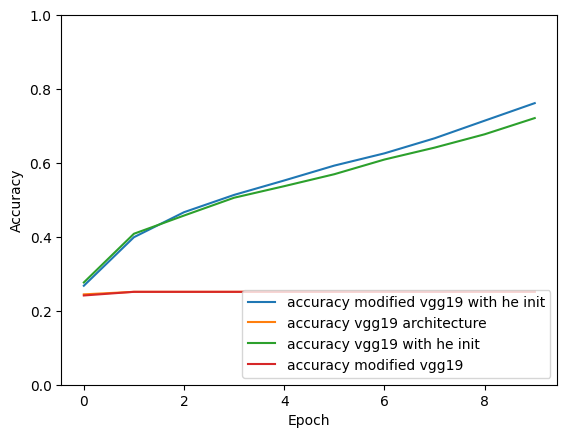

In [ ]:
for i, history in enumerate(hist_resume):
  plt.plot(history.history['accuracy'], label=f'accuracy {m_labels[i]}')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
plt.legend(loc='lower right')

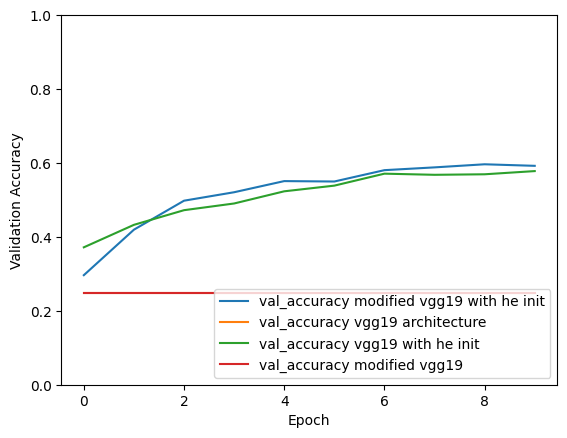

In [ ]:
for i, history in enumerate(hist_resume):
  plt.plot(history.history['val_accuracy'], label = f'val_accuracy {m_labels[i]}')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.ylim(0, 1.0)
plt.legend(loc='lower right')

### Model Tunning*

In [ ]:
augmentation_levels = [None, 'light', 'medium', 'strong']
drop_rates = np.linspace(0.0, 0.5, 5)
lrs = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]

In [ ]:
def tune(values, attr=None, attr_fit=None, second_attr={}, second_attr_fit={}):

  result=list()

  for val in values:
    X_train_model = X_train.reshape(-1,48,48,1)
    X_val_model = X_val.reshape(-1,48,48,1)

    model_kwargs = {} | second_attr
    fit_kwargs = {} | second_attr_fit

    if attr is not None:
      model_kwargs[attr] = val
    if attr_fit is not None:
      fit_kwargs[attr_fit] = val

    model = vgg_model(X_train_model, y_train_one_hot, labels, **model_kwargs)

    model.summary()

    metr, hist = fit_model(
      model,
      X_train_model, y_train_one_hot,
      X_val_model, y_val_one_hot,
      labels,
      epochs=10,
      **fit_kwargs
    )

    result.append((metr, hist))
  return result


In [ ]:
def plot_tune(metric, results, values):
  for val, (metrics_df, hist) in zip(values, results):
    y = hist.history[metric]
    x = np.arange(1, len(y) + 1)
    plt.plot(x, y, label=f'{metric}-{val}')
  plt.xlabel('Epoch')
  plt.ylabel(metric)
  plt.ylim(0, 1.0)
  plt.legend()
  plt.legend(loc='lower right')

#### Augmentation*

In [ ]:
aug_tuning = tune(augmentation_levels, attr='aug_strength', second_attr={'drop_rate':0.5})

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │         3,59

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_strong_1 (RandomFlip)       │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_strong_2 (RandomRotation)   │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_strong_3                    │ (None, 48, 48, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_strong_4 (RandomZoom)       │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_strong_5 (RandomContrast)   │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 55s 218ms/step - accuracy: 0.2352 - loss: 1.9077 - val_accuracy: 0.2476 - val_loss: 1.8123
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 209ms/step - accuracy: 0.2511 - loss: 1.8177 - val_accuracy: 0.2476 - val_loss: 1.8079
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 83s 212ms/step - accuracy: 0.2515 - loss: 1.8072 - val_accuracy: 0.2476 - val_loss: 1.8049
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 209ms/step - accuracy: 0.2512 - loss: 1.8023 - val_accuracy: 0.2476 - val_loss: 1.7887
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 210ms/step - accuracy: 0.2585 - loss: 1.7853 - val_accuracy: 0.2844 - val_loss: 1.7318
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 211ms/step - accuracy: 0.2574 - loss: 1.7897 - val_accuracy: 0.2646 - val_loss: 1.7377
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 52s 231ms/step - accuracy: 0.2764 - loss: 1.7501 - val_accuracy: 0.3165 - val_loss: 1.6711
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 210ms/step - accuracy: 0.2881 - loss: 1

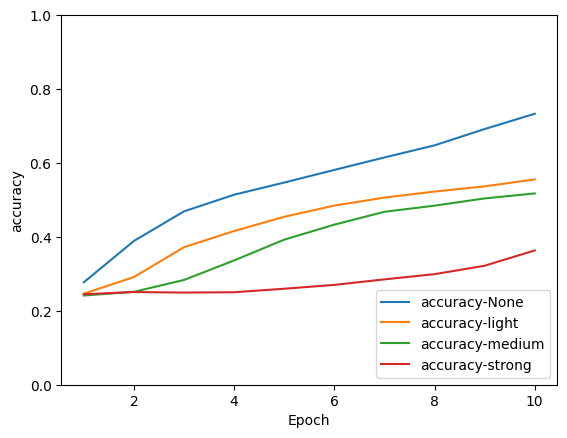

In [ ]:
plot_tune("accuracy", aug_tuning, augmentation_levels)

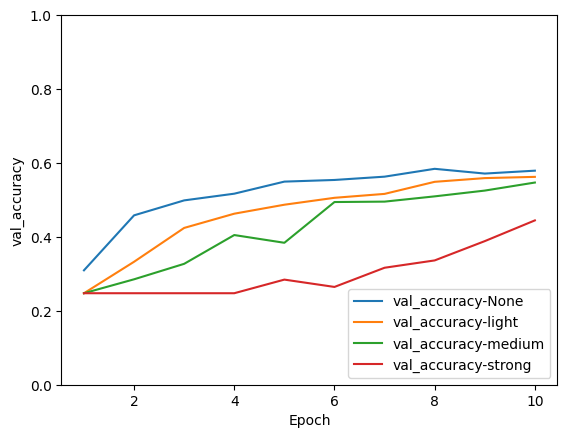

In [ ]:
plot_tune("val_accuracy", aug_tuning, augmentation_levels)

#### Dropout rate*

In [ ]:
dr_tuning = tune(drop_rates, attr='drop_rate', second_attr={'aug_strength':'light'})

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_1 (RandomFlip)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_2 (RandomRotation)    │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_3 (RandomTranslation) │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_4 (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,80

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_1 (RandomFlip)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_2 (RandomRotation)    │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_3 (RandomTranslation) │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_4 (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,80

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 55s 215ms/step - accuracy: 0.2348 - loss: 1.8737 - val_accuracy: 0.2476 - val_loss: 1.8581
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 49s 216ms/step - accuracy: 0.2843 - loss: 1.7583 - val_accuracy: 0.3768 - val_loss: 1.6015
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 212ms/step - accuracy: 0.3876 - loss: 1.5536 - val_accuracy: 0.4292 - val_loss: 1.4731
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 212ms/step - accuracy: 0.4241 - loss: 1.4670 - val_accuracy: 0.4728 - val_loss: 1.3660
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 211ms/step - accuracy: 0.4559 - loss: 1.3788 - val_accuracy: 0.5040 - val_loss: 1.2942
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 212ms/step - accuracy: 0.4917 - loss: 1.3171 - val_accuracy: 0.4965 - val_loss: 1.3193
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 47s 210ms/step - accuracy: 0.5161 - loss: 1.2666 - val_accuracy: 0.5233 - val_loss: 1.2530
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 212ms/step - accuracy: 0.5419 - loss: 1

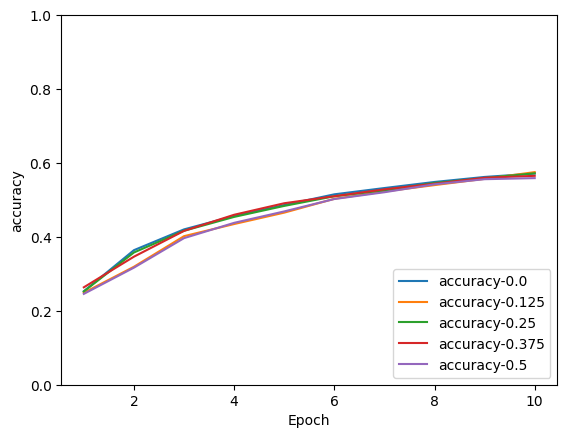

In [ ]:
plot_tune("accuracy", dr_tuning, drop_rates)

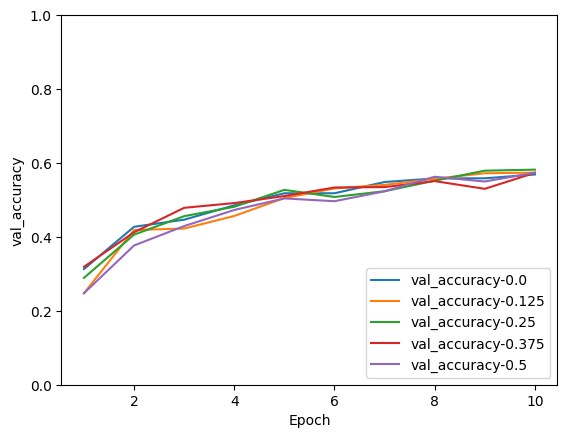

In [ ]:
plot_tune("val_accuracy", dr_tuning, drop_rates)

#### Learning rate*

In [ ]:
lr_tuning = tune(lrs, attr_fit='learning_rate', second_attr={'aug_strength':'light', 'drop_rate':0.0})

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_1 (RandomFlip)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_2 (RandomRotation)    │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_3 (RandomTranslation) │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_4 (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,80

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_1 (RandomFlip)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_2 (RandomRotation)    │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_3 (RandomTranslation) │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_4 (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,80

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 56s 225ms/step - accuracy: 0.2275 - loss: 415.6590 - val_accuracy: 0.2476 - val_loss: 1.8123
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 213ms/step - accuracy: 0.2486 - loss: 1.8146 - val_accuracy: 0.2476 - val_loss: 1.8137
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 83s 218ms/step - accuracy: 0.2511 - loss: 1.8103 - val_accuracy: 0.2476 - val_loss: 1.8130
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 214ms/step - accuracy: 0.2499 - loss: 1.8125 - val_accuracy: 0.2476 - val_loss: 1.8140
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 214ms/step - accuracy: 0.2485 - loss: 1.8134 - val_accuracy: 0.2476 - val_loss: 1.8197
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 49s 218ms/step - accuracy: 0.2499 - loss: 1.8141 - val_accuracy: 0.2476 - val_loss: 1.8130
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 214ms/step - accuracy: 0.2471 - loss: 1.8139 - val_accuracy: 0.2476 - val_loss: 1.8128
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 215ms/step - accuracy: 0.2515 - loss:

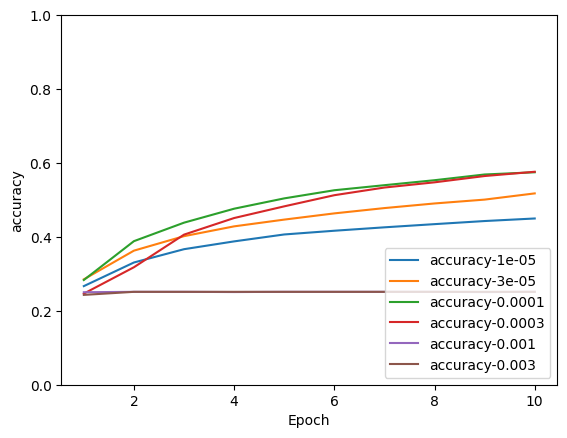

In [ ]:
plot_tune("accuracy", lr_tuning, lrs)

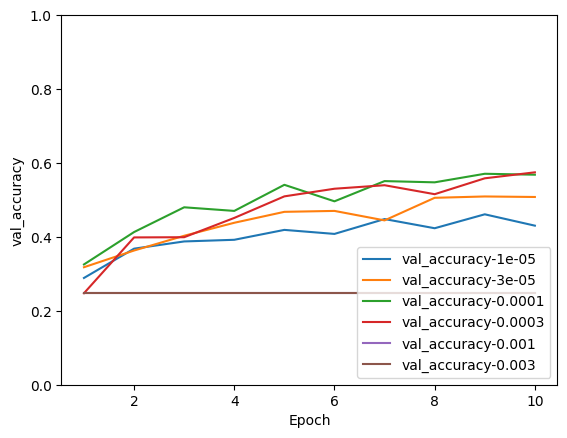

In [ ]:
plot_tune("val_accuracy", lr_tuning, lrs)

### Optimal model

In [ ]:
X_train_model = X_train.reshape(-1,48,48,1)
X_val_model = X_val.reshape(-1,48,48,1)
X_test_model = X_test.reshape(-1,48,48,1)

opt_model = vgg_model(X_train_model, y_train_one_hot, labels, drop_rate=0.0, aug_strength='light')

opt_model.summary()

opt_metr, opt_hist = fit_model(
  opt_model,
  X_train_model, y_train_one_hot,
  X_val_model, y_val_one_hot,
  labels,
  epochs=30,
  learning_rate=lrs[3]
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_1 (RandomFlip)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_2 (RandomRotation)    │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_3 (RandomTranslation) │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_4 (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,80

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 67s 248ms/step - accuracy: 0.2377 - loss: 1.8638 - val_accuracy: 0.2476 - val_loss: 1.7974
Epoch 2/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 215ms/step - accuracy: 0.2810 - loss: 1.7667 - val_accuracy: 0.3852 - val_loss: 1.5880
Epoch 3/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 216ms/step - accuracy: 0.3840 - loss: 1.5652 - val_accuracy: 0.4320 - val_loss: 1.4678
Epoch 4/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 213ms/step - accuracy: 0.4277 - loss: 1.4531 - val_accuracy: 0.4926 - val_loss: 1.3569
Epoch 5/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 213ms/step - accuracy: 0.4706 - loss: 1.3664 - val_accuracy: 0.4733 - val_loss: 1.4003
Epoch 6/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 213ms/step - accuracy: 0.4967 - loss: 1.3049 - val_accuracy: 0.5216 - val_loss: 1.2593
Epoch 7/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 214ms/step - accuracy: 0.5246 - loss: 1.2427 - val_accuracy: 0.5412 - val_loss: 1.1875
Epoch 8/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 212ms/step - accuracy: 0.5423 - loss: 1

Text(0, 0.5, 'accuracy_score')

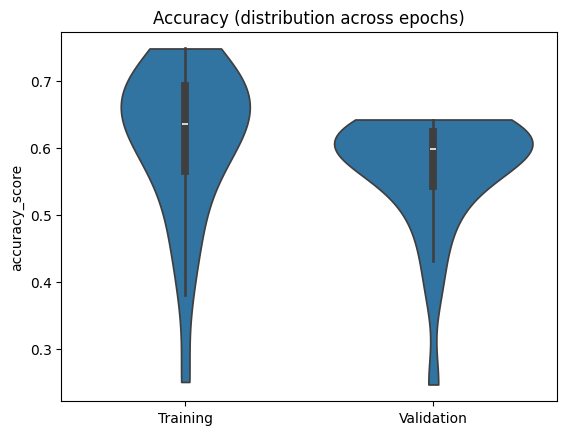

In [ ]:
acc_df = opt_metr[["epoch", "type", "accuracy score"]].copy()

sns.violinplot(
    data=acc_df,
    x="type", y="accuracy score", cut =0
)
plt.title("Accuracy (distribution across epochs)")
plt.xlabel("")
plt.ylabel("accuracy_score")

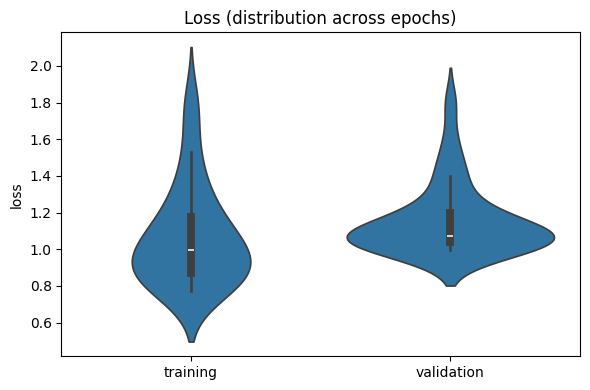

In [ ]:
loss_long = pd.DataFrame({
    "epoch": range(1, len(opt_hist.history["loss"]) + 1),
    "training": opt_hist.history["loss"],
    "validation": opt_hist.history.get("val_loss")  # might be None if you didn't pass validation
}).melt(id_vars="epoch", var_name="type", value_name="loss")

loss_long = loss_long.dropna(subset=["loss"])  # in case val_loss is missing

plt.figure(figsize=(6,4))
sns.violinplot(
    data=loss_long,
    x="type", y="loss"
)
plt.title("Loss (distribution across epochs)")
plt.xlabel("")
plt.ylabel("loss")
plt.tight_layout()
plt.show()

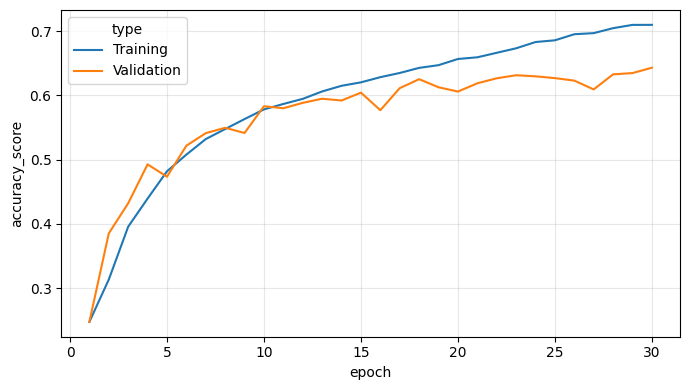

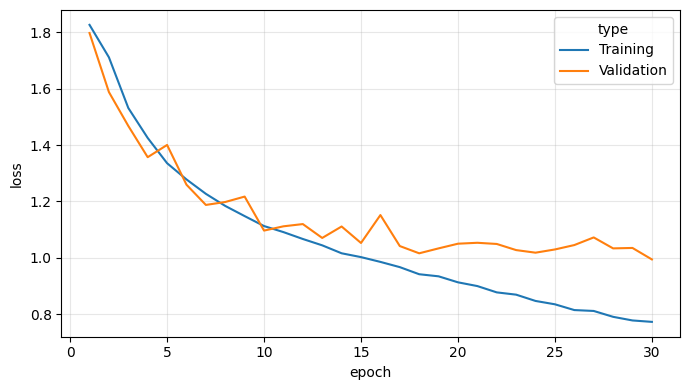

In [ ]:
plt.figure(figsize=(7,4))
plt.plot(range(1,31), opt_hist.history["accuracy"], label="Training")
plt.plot(range(1,31), opt_hist.history["val_accuracy"], label="Validation")
plt.xlabel("epoch")
plt.ylabel("accuracy_score")
plt.legend(title="type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Loss plot ----
plt.figure(figsize=(7,4))
plt.plot(range(1,31), opt_hist.history["loss"], label="Training")
plt.plot(range(1,31), opt_hist.history["val_loss"], label="Validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend(title="type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
opt_model.save("vgg19_emotion.keras")

In [ ]:
opt_metr

,accuracy score,balanced accuracy score,precision score,recall score,f1 score,type,epoch
0,0.251334,0.142857,0.063169,0.251334,0.100962,Training,0
1,0.381655,0.292183,0.308216,0.381655,0.296769,Training,1
2,0.435903,0.343233,0.399723,0.435903,0.373474,Training,2
3,0.480145,0.391039,0.460619,0.480145,0.453886,Training,3
4,0.484224,0.375959,0.496474,0.484224,0.448134,Training,4
5,0.530767,0.431513,0.524060,0.530767,0.505430,Training,5
6,0.559844,0.461022,0.530283,0.559844,0.534664,Training,6
7,0.569187,0.484272,0.559843,0.569187,0.560986,Training,7
8,0.564829,0.473092,0.567003,0.564829,0.528973,Training,8
9,0.602552,0.526328,0.602088,0.602552,0.584696,Training,9


In [ ]:
opt_y_pred = opt_model.predict(X_test.reshape(-1, 48, 48, 1))
opt_y_pred.shape

113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step


(3585, 7)

In [ ]:
opt_y_pred_target = np.argmax(opt_y_pred, axis=1)
opt_y_pred_target.shape

(3585,)

In [26]:
def plot_conf_matrix(model, target_eval, target_true, title=''):

  y_pred = model.predict(target_eval)
  y_pred.shape

  target_pred = np.argmax(y_pred, axis=1)

  cm = metrics.confusion_matrix(target_true, target_pred, labels=list(labels.keys()) )
  disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm,
                                display_labels=labels.values())

  disp.plot()
  plt.title(title)
  plt.show()

In [27]:
def plot_error_predicted(model, target_eval, target_true, title='', amount=10):

  y_pred = model.predict(target_eval)
  y_pred.shape

  target_pred = np.argmax(y_pred, axis=1)

  fig, axs = plt.subplots(len(labels), amount, figsize=(amount*2, len(labels)*(1.95)))

  distrib ={}
  indexing = {}

  for i in labels.keys():
      mask = (target_true==i) & (target_true!=target_pred)
      imgs = target_eval[mask]
      ys = target_pred[mask]
      s = amount if amount<len(imgs) else len(imgs)
      for j in range(amount):
          y = ys[j]
          img = imgs[j]

          axs[i][j].imshow(img, cmap="gray")
          axs[i][j].set_title(f'T:{labels[i]}, P:{labels[y]}')
          axs[i][j].axis('off')
          j+=1

In [ ]:
X_train_model.shape, X_train_model[0].shape, y_train.shape

((28683, 48, 48, 1), (48, 48, 1), (28683,))

897/897 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step


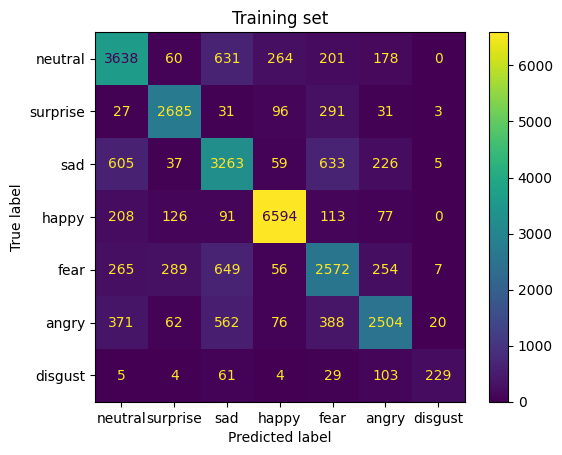

In [ ]:
plot_conf_matrix(opt_model, X_train_model, y_train, 'Training set')

897/897 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step


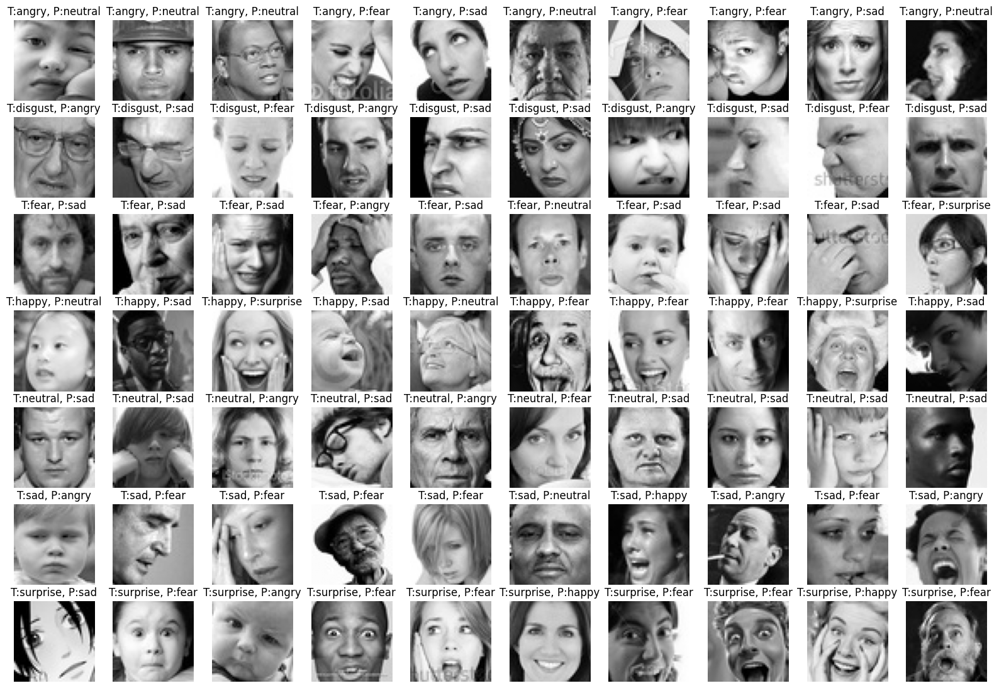

In [ ]:
plot_error_predicted(opt_model, X_train_model, y_train, 'Training set', 10)

112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step


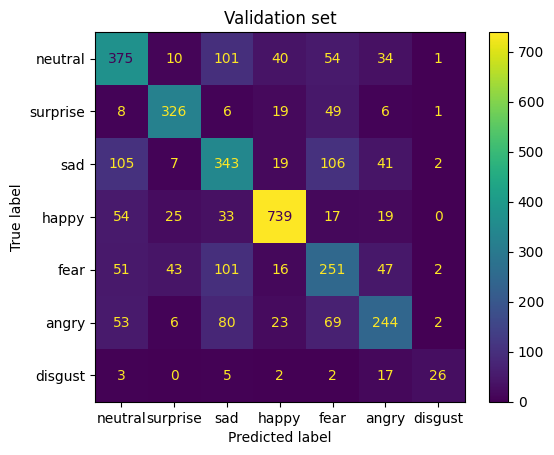

In [ ]:
plot_conf_matrix(opt_model, X_val_model, y_val, 'Validation set')

112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step


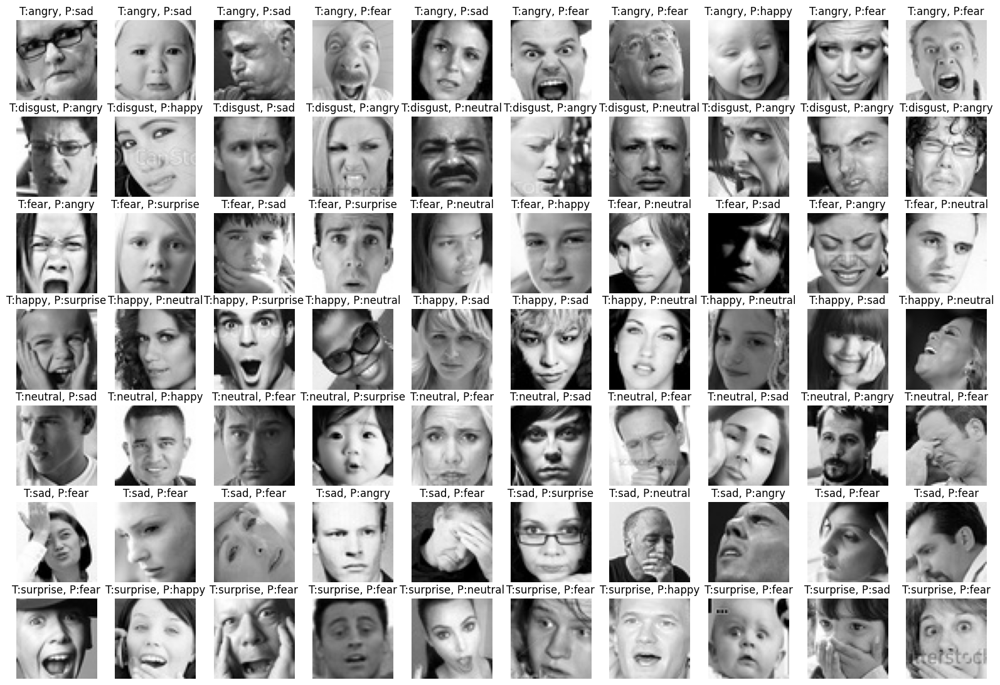

In [ ]:
plot_error_predicted(opt_model, X_val_model, y_val, 'Validation set')

## Model 3 (Hypotesis verification)

In [ ]:
def model_3(X_train, y_train, labels):
  '''
	X_train: numpy array with values of x to train
  y_train: numpy array with target values for train task
  labels: possible classes of classification

  return
  model: model to train
	'''
  model = models.Sequential()

  ## Input Block
  input_shape = X_train.shape[1:]
  model.add(tf.keras.Input(shape=input_shape, name='input_gray'))

  ## Grayscale to RGB
  model.add(layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x), name='gray_to_rgb'))

  ## Block 1
  model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2)))

  ## Block 2
  model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2)))

  ## Block 3
  model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_initializer='he_normal'))
  model.add(layers.MaxPooling2D((2, 2), strides=(2, 2)))

  ## Final block (Result)
  model.add(layers.Flatten())
  model.add(layers.Dense(64, activation='relu', kernel_initializer='he_normal'))
  model.add(layers.Dense(len(labels.keys()), activation='softmax', kernel_initializer='he_normal'))

  return model

In [ ]:
model = model_3(X_train.reshape(-1,48,48,1), y_train_one_hot, labels)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 204,295 (798.03 KB)

 Trainable params: 204,295 (798.03 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
summary_metrics, history = fit_model(
    model,
    X_train.reshape(-1,48,48,1), y_train_one_hot,
    X_val.reshape(-1,48,48,1), y_val_one_hot,
    labels,
    learning_rate=3e-4,
    epochs=10
)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step - accuracy: 0.3046 - loss: 1.7453 - val_accuracy: 0.3720 - val_loss: 1.6211
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.3960 - loss: 1.5775 - val_accuracy: 0.4139 - val_loss: 1.5335
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.4421 - loss: 1.4779 - val_accuracy: 0.4591 - val_loss: 1.4383
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.4709 - loss: 1.4061 - val_accuracy: 0.4745 - val_loss: 1.4037
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.4920 - loss: 1.3459 - val_accuracy: 0.4853 - val_loss: 1.3586
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.5133 - loss: 1.2974 - val_accuracy: 0.5046 - val_loss: 1.3189
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5294 - loss: 1.2575 - val_accuracy: 0.5001 - val_loss: 1.3218
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5430 - loss: 1.2159 - val_acc

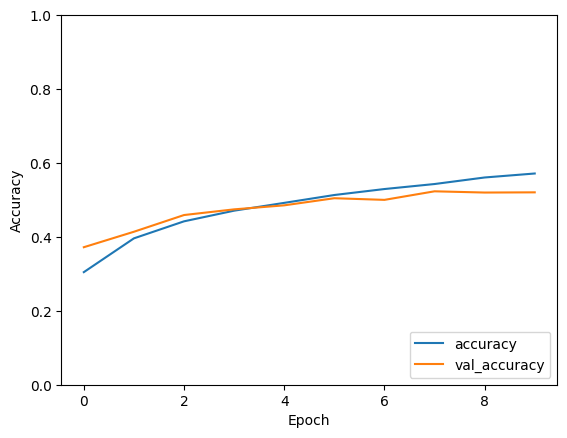

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
plt.legend(loc='lower right')

In [28]:
def model_3_pretrained(
    num_classes,
    input_shape=(48, 48, 1)
):
  base_model = tf.keras.applications.VGG19(
      include_top=False,
      weights="imagenet",
      pooling="avg"
  )
  base_model.trainable = False

  model = models.Sequential()
  model.add(tf.keras.Input(shape=input_shape))
  model.add(layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x)))
  model.add(layers.Resizing(224, 224))
  model.add(layers.Lambda(tf.keras.applications.vgg19.preprocess_input))

  # VGG19 model
  model.add(base_model)

  ## Top (Result)
  model.add(layers.Flatten(name='flatten'))

  model.add(layers.Dense(4096, activation="relu", kernel_initializer='he_normal', name="fc1"))

  model.add(layers.Dense(4096, activation="relu", kernel_initializer='he_normal', name="fc2"))

  model.add(layers.Dense(len(labels.keys()), activation='softmax', kernel_initializer='he_normal', name='predictions'))

  return model, base_model

In [ ]:
model_pretrained, base_vgg19 = model_3_pretrained(len(labels))

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
model_pretrained.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 512)            │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │     2,101,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 7)              │        28,679 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,935,623 (148.53 MB)

 Trainable params: 18,911,239 (72.14 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

In [ ]:
summary_metrics_pretrained, history_pretrained = fit_model(
    model_pretrained,
    X_train_model, y_train_one_hot,
    X_val_model, y_val_one_hot,
    labels,
    learning_rate=3e-4,
    epochs=10
)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 628s 3s/step - accuracy: 0.1974 - loss: 2.5354 - val_accuracy: 0.1426 - val_loss: 2.3748
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 444s 2s/step - accuracy: 0.2014 - loss: 1.9569 - val_accuracy: 0.1158 - val_loss: 2.2625
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 444s 2s/step - accuracy: 0.2045 - loss: 1.9162 - val_accuracy: 0.2481 - val_loss: 2.1966
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 446s 2s/step - accuracy: 0.2089 - loss: 1.9070 - val_accuracy: 0.1331 - val_loss: 1.9374
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 441s 2s/step - accuracy: 0.2125 - loss: 1.8839 - val_accuracy: 0.2476 - val_loss: 1.8324
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 442s 2s/step - accuracy: 0.2182 - loss: 1.8494 - val_accuracy: 0.1739 - val_loss: 1.9193
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 456s 2s/step - accuracy: 0.2265 - loss: 1.8495 - val_accuracy: 0.1716 - val_loss: 1.9683
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 444s 2s/step - accuracy: 0.2258 - loss: 1.8473 - val_accu

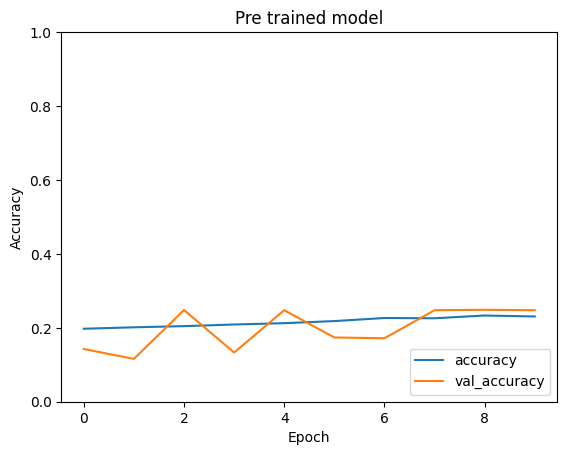

In [ ]:
plt.plot(history_pretrained.history['accuracy'], label='accuracy')
plt.plot(history_pretrained.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Pre trained model')
plt.ylim(0, 1.0)
plt.legend(loc='lower right')

### Model Tunning*

In [ ]:
lrs = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3]

In [ ]:
results_model_3=list()

for lr in lrs:

  model = model_3(X_train.reshape(-1,48,48,1), y_train_one_hot, labels)

  metr, hist = fit_model(
    model,
    X_train_model, y_train_one_hot,
    X_val_model, y_val_one_hot,
    labels,
    learning_rate=lr,
    epochs=10
  )

  results_model_3.append((metr, hist))


Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.2085 - loss: 1.9660 - val_accuracy: 0.2509 - val_loss: 1.8275
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.2485 - loss: 1.8164 - val_accuracy: 0.2565 - val_loss: 1.8060
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.2558 - loss: 1.8013 - val_accuracy: 0.2601 - val_loss: 1.7964
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.2630 - loss: 1.7881 - val_accuracy: 0.2707 - val_loss: 1.7809
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.2726 - loss: 1.7762 - val_accuracy: 0.2774 - val_loss: 1.7702
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.2794 - loss: 1.7661 - val_accuracy: 0.2877 - val_loss: 1.7597
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.2898 - loss: 1.7546 - val_accuracy: 0.2891 - val_loss: 1.7510
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - accuracy: 0.2973 - loss: 1.7436 - val_acc

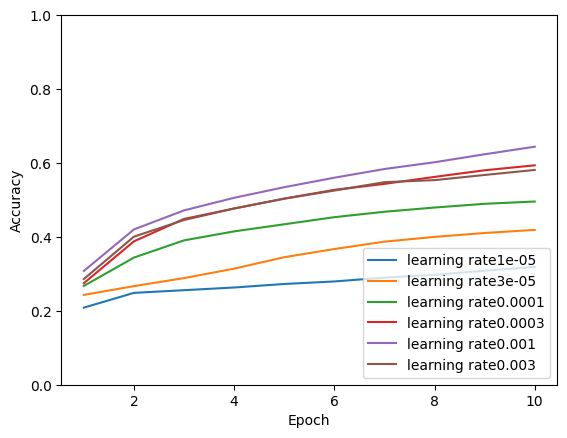

In [ ]:
for lr, (metrics_df, hist) in zip(lrs, results_model_3):
  y = hist.history["accuracy"]
  x = np.arange(1, len(y) + 1)
  plt.plot(x, y, label=f'learning rate{lr}')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1.0)
plt.legend()
plt.legend(loc='lower right')

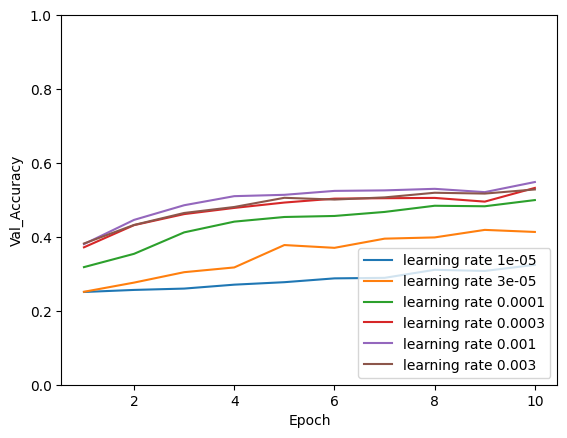

In [ ]:
for lr, (metrics_df, hist) in zip(lrs, results_model_3):
  y = hist.history["val_accuracy"]
  x = np.arange(1, len(y) + 1)
  plt.plot(x, y, label=f'learning rate {lr}')
plt.xlabel('Epoch')
plt.ylabel('Val_Accuracy')
plt.ylim(0, 1.0)
plt.legend()
plt.legend(loc='lower right')

In [30]:
lrs_pretained = [1e-4, 4e-4, 8e-4, 2e-3, 6e-3]

In [31]:
results_model_3_pretrained=list()

for lr in lrs_pretained:

  model , base_vgg19 = model_3_pretrained(len(labels))

  metr, hist = fit_model(
    model,
    X_train_model, y_train_one_hot,
    X_val_model, y_val_one_hot,
    labels,
    learning_rate=lr,
    epochs=5
  )

  results_model_3_pretrained.append((metr, hist))


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 521s 2s/step - accuracy: 0.1974 - loss: 2.0244 - val_accuracy: 0.1158 - val_loss: 2.0024
Epoch 2/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 446s 2s/step - accuracy: 0.2047 - loss: 1.8924 - val_accuracy: 0.1716 - val_loss: 2.1057
Epoch 3/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 399s 2s/step - accuracy: 0.1988 - loss: 1.9338 - val_accuracy: 0.1331 - val_loss: 2.3869
Epoch 4/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 399s 2s/step - accuracy: 0.2058 - loss: 1.9079 - val_accuracy: 0.1716 - val_loss: 2.0586
Epoch 5/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 399s 2s/step - accuracy: 0.2005 - loss: 1.9218 - val_accuracy: 0.1331 - val_loss: 1.8798
Epoch 1/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 409s 2s/step - accuracy: 0.1961 - loss: 2.6096 - val_accuracy: 0.2476 - val_loss: 2.0400
Epoch 2/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 401s 2s/step - accuracy: 0.2038 - loss: 1.9196 - val_accuracy: 0.2476 - val_loss: 1.9699
Epoch 3/5
225/225 ━━━━━━━━━━━━━━━━━━━━ 399s 2s/step -

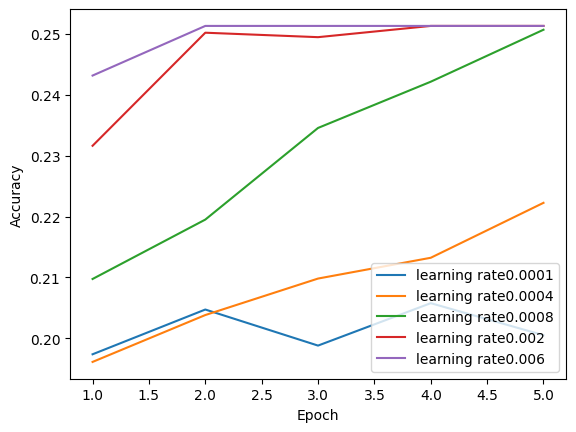

In [32]:
for lr, (metrics_df, hist) in zip(lrs_pretained, results_model_3_pretrained):
  y = hist.history["accuracy"]
  x = np.arange(1, len(y) + 1)
  plt.plot(x, y, label=f'learning rate{lr}')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.legend(loc='lower right')

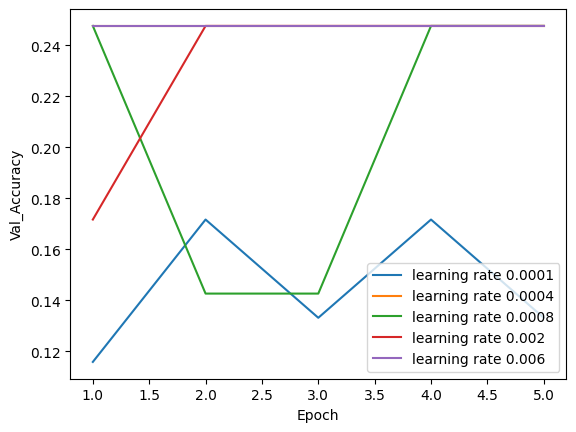

In [33]:
for lr, (metrics_df, hist) in zip(lrs_pretained, results_model_3_pretrained):
  y = hist.history["val_accuracy"]
  x = np.arange(1, len(y) + 1)
  plt.plot(x, y, label=f'learning rate {lr}')
plt.xlabel('Epoch')
plt.ylabel('Val_Accuracy')
plt.legend()
plt.legend(loc='lower right')

### Optimal model

In [ ]:
X_train_model = X_train.reshape(-1,48,48,1)
X_val_model = X_val.reshape(-1,48,48,1)
X_test_model = X_test.reshape(-1,48,48,1)

opt_model = model_3(X_train_model, y_train, labels)

opt_metrics, opt_hist = fit_model(
    opt_model,
    X_train_model, y_train_one_hot,
    X_val_model, y_val_one_hot,
    labels,
    learning_rate=lrs[4]
)

Epoch 1/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.3050 - loss: 1.7633 - val_accuracy: 0.4055 - val_loss: 1.5721
Epoch 2/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.4273 - loss: 1.5069 - val_accuracy: 0.4382 - val_loss: 1.4475
Epoch 3/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.4768 - loss: 1.3859 - val_accuracy: 0.4669 - val_loss: 1.4065
Epoch 4/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5077 - loss: 1.3102 - val_accuracy: 0.5183 - val_loss: 1.2959
Epoch 5/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.5354 - loss: 1.2418 - val_accuracy: 0.5336 - val_loss: 1.2578
Epoch 6/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.5596 - loss: 1.1882 - val_accuracy: 0.5227 - val_loss: 1.2652
Epoch 7/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.5770 - loss: 1.1386 - val_accuracy: 0.5345 - val_loss: 1.2352
Epoch 8/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.5951 - loss: 1.0928 - val_acc

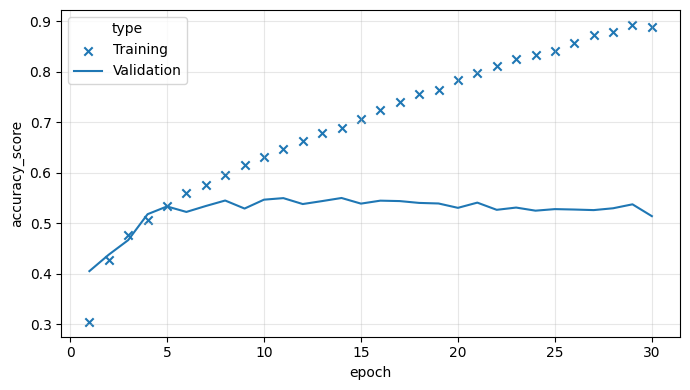

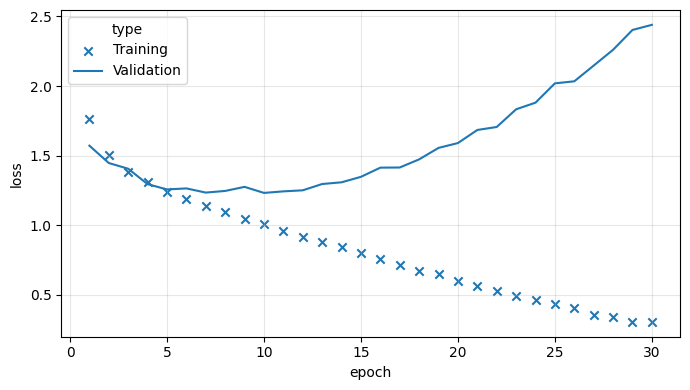

In [ ]:
plt.figure(figsize=(7,4))
plt.scatter(range(1,31), opt_hist.history["accuracy"], label="Training", marker='x')
plt.plot(range(1,31), opt_hist.history["val_accuracy"], label="Validation")
plt.xlabel("epoch")
plt.ylabel("accuracy_score")
plt.legend(title="type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.scatter(range(1,31), opt_hist.history["loss"], label="Training", marker='x')
plt.plot(range(1,31), opt_hist.history["val_loss"], label="Validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend(title="type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
opt_metrics

,accuracy score,balanced accuracy score,precision score,recall score,f1 score,type,epoch
0,0.395112,0.319301,0.424779,0.395112,0.373900,Training,0
1,0.443712,0.362535,0.416498,0.443712,0.399040,Training,1
2,0.477705,0.381650,0.461800,0.477705,0.426227,Training,2
3,0.535648,0.438737,0.521501,0.535648,0.514513,Training,3
4,0.562319,0.474702,0.555672,0.562319,0.545397,Training,4
5,0.575428,0.496780,0.596654,0.575428,0.576188,Training,5
6,0.602308,0.521270,0.596691,0.602308,0.591464,Training,6
7,0.618799,0.550766,0.646541,0.618799,0.613843,Training,7
8,0.617962,0.557292,0.649932,0.617962,0.625198,Training,8
9,0.647073,0.583895,0.648441,0.647073,0.638931,Training,9


112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


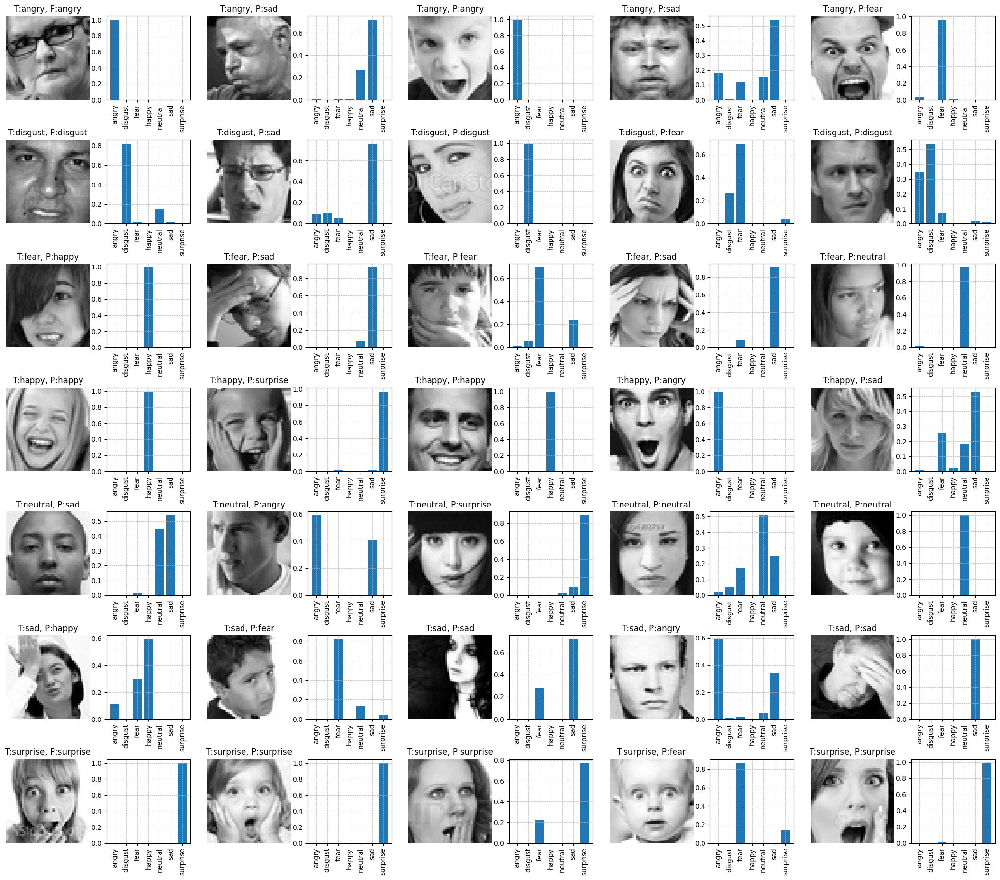

In [ ]:
y_pred = opt_model.predict(X_val_model)
y_pred.shape

target_pred = np.argmax(y_pred, axis=1)
fig, axs = plt.subplots(len(labels), 10, figsize=(13*2, len(labels)*(3.20)))

distrib ={}
indexing = {}

for i in labels.keys():
    mask = (y_val==i)
    imgs = X_val_model[mask]
    ys = target_pred[mask]
    s = 5 if 5<len(imgs) else len(imgs)
    for j in range(0,10,2):
        y = ys[j]
        img = imgs[j]

        axs[i][j].imshow(img, cmap="gray")
        axs[i][j].set_title(f'T:{labels[i]}, P:{labels[y]}')
        axs[i][j].axis('off')

        x_bar=list(labels.keys())
        y_bar = [y_pred[mask][j][v] for v in list(labels.keys())]
        axs[i][j+1].bar(x_bar, y_bar)
        axs[i][j+1].set_xticks(x_bar, labels.values(), rotation='vertical')
        axs[i][j+1].set_box_aspect(1)
        axs[i][j+1].grid(linestyle = '--', linewidth = 0.5)

        j+=1

112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


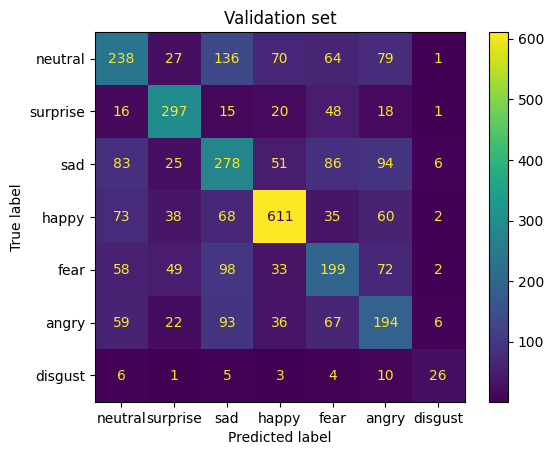

In [ ]:
plot_conf_matrix(opt_model, X_val_model, y_val, 'Validation set')

In [31]:
opt_model_pretrained , base_vgg19 = model_3_pretrained(len(labels))

opt_metr_pretrained, opt_hist_pretrained = fit_model(
  opt_model_pretrained,
  X_train_model, y_train_one_hot,
  X_val_model, y_val_one_hot,
  labels,
  learning_rate=lrs_pretained[1],
  epochs=10
)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 558s 2s/step - accuracy: 0.1996 - loss: 2.7570 - val_accuracy: 0.1426 - val_loss: 1.9782
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 449s 2s/step - accuracy: 0.2037 - loss: 1.9273 - val_accuracy: 0.2501 - val_loss: 1.9523
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 444s 2s/step - accuracy: 0.2050 - loss: 1.8854 - val_accuracy: 0.2476 - val_loss: 1.9450
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 445s 2s/step - accuracy: 0.2065 - loss: 1.8745 - val_accuracy: 0.2476 - val_loss: 1.8367
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 447s 2s/step - accuracy: 0.2238 - loss: 1.8417 - val_accuracy: 0.2476 - val_loss: 1.9015
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 480s 2s/step - accuracy: 0.2291 - loss: 1.8389 - val_accuracy: 0.1426 - val_loss: 1.8663
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 447s 2s/step - accuracy: 0.2289 - loss: 1.8306 - val_accuracy: 0.2476 - val_loss: 1.8236
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 480s 2s/step - accuracy: 0.2409 - loss: 1.8272 - val_accu

In [34]:
base_vgg19.trainable = True

opt_metr_pretrained_2, opt_hist_pretrained_2 = fit_model(
  opt_model_pretrained,
  X_train_model, y_train_one_hot,
  X_val_model, y_val_one_hot,
  labels,
  learning_rate=lrs_pretained[1],
  epochs=10
)

Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 904s 4s/step - accuracy: 0.2453 - loss: 1.9171 - val_accuracy: 0.2476 - val_loss: 1.8166
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 809s 4s/step - accuracy: 0.2513 - loss: 1.8148 - val_accuracy: 0.2476 - val_loss: 1.8149
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 808s 4s/step - accuracy: 0.2471 - loss: 1.8425 - val_accuracy: 0.2476 - val_loss: 1.8168
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 803s 4s/step - accuracy: 0.2513 - loss: 1.8117 - val_accuracy: 0.2476 - val_loss: 1.8158
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 804s 4s/step - accuracy: 0.2513 - loss: 1.8116 - val_accuracy: 0.2476 - val_loss: 1.8137
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 803s 4s/step - accuracy: 0.2513 - loss: 1.8107 - val_accuracy: 0.2476 - val_loss: 1.8143
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 862s 4s/step - accuracy: 0.2513 - loss: 1.8108 - val_accuracy: 0.2476 - val_loss: 1.8136
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 854s 4s/step - accuracy: 0.2513 - loss: 1.8110 - val_accu

In [35]:
train_acc = (
    opt_hist_pretrained.history["accuracy"] +
    opt_hist_pretrained_2.history["accuracy"]
)

val_acc = (
    opt_hist_pretrained.history["val_accuracy"] +
    opt_hist_pretrained_2.history["val_accuracy"]
)

train_loss = (
    opt_hist_pretrained.history["loss"] +
    opt_hist_pretrained_2.history["loss"]
)

val_loss = (
    opt_hist_pretrained.history["val_loss"] +
    opt_hist_pretrained_2.history["val_loss"]
)

epochs = range(1, len(train_acc) + 1)

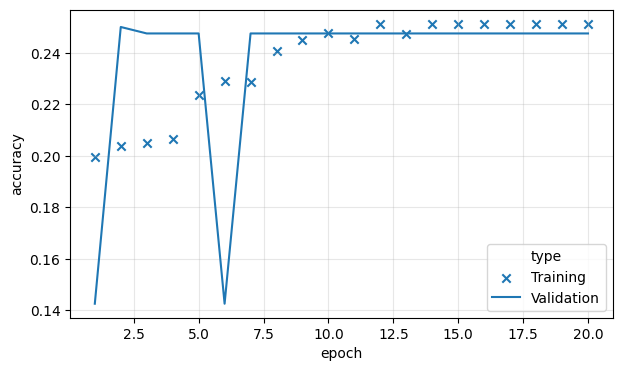

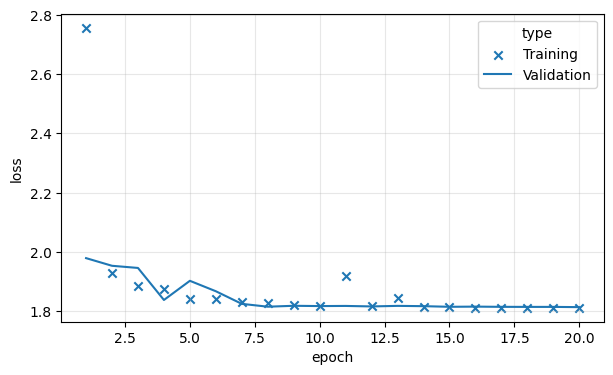

In [36]:
plt.figure(figsize=(7,4))
plt.scatter(epochs, train_acc, label="Training", marker="x")
plt.plot(epochs, val_acc, label="Validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend(title="type")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7,4))
plt.scatter(epochs, train_loss, label="Training", marker="x")
plt.plot(epochs, val_loss, label="Validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend(title="type")
plt.grid(True, alpha=0.3)
plt.show()

112/112 ━━━━━━━━━━━━━━━━━━━━ 25s 219ms/step


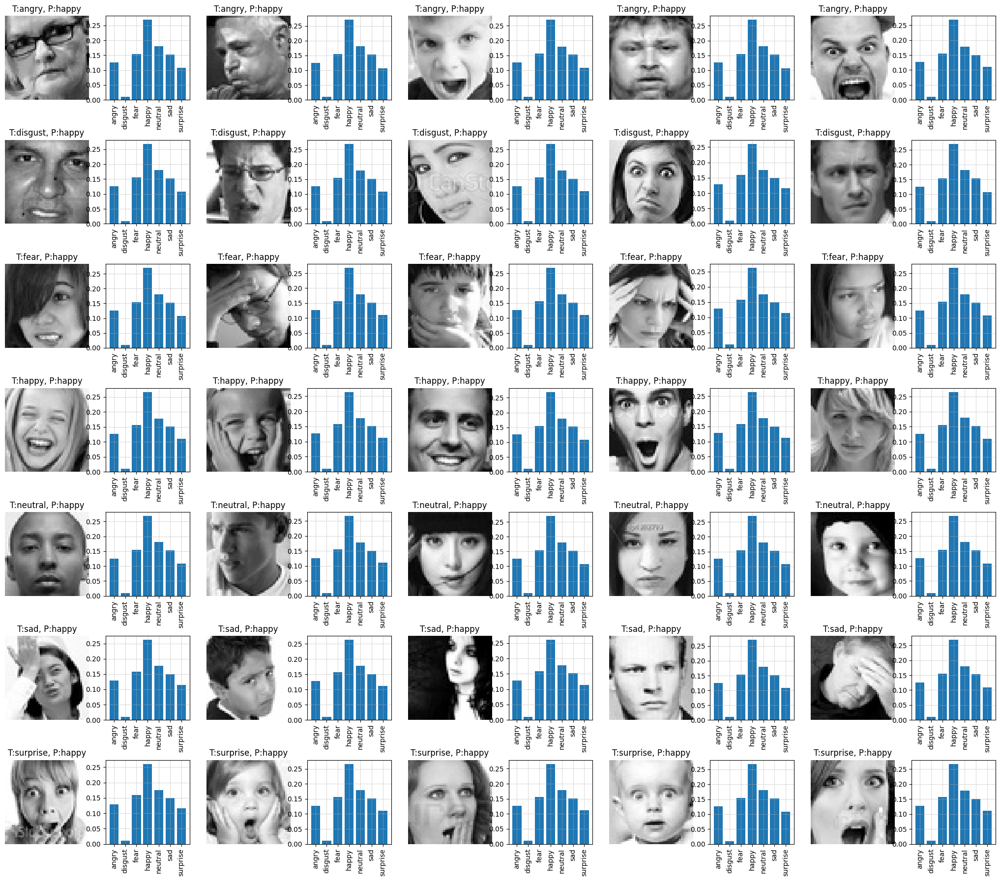

In [41]:
y_pred = opt_model_pretrained.predict(X_val_model)
y_pred.shape

target_pred = np.argmax(y_pred, axis=1)
fig, axs = plt.subplots(len(labels), 10, figsize=(13*2, len(labels)*(3.20)))

distrib ={}
indexing = {}

for i in labels.keys():
    mask = (y_val==i)
    imgs = X_val_model[mask]
    ys = target_pred[mask]
    s = 5 if 5<len(imgs) else len(imgs)
    for j in range(0,10,2):
        y = ys[j]
        img = imgs[j]

        axs[i][j].imshow(img, cmap="gray")
        axs[i][j].set_title(f'T:{labels[i]}, P:{labels[y]}')
        axs[i][j].axis('off')

        x_bar=list(labels.keys())
        y_bar = [y_pred[mask][j][v] for v in list(labels.keys())]
        axs[i][j+1].bar(x_bar, y_bar)
        axs[i][j+1].set_xticks(x_bar, labels.values(), rotation='vertical')
        axs[i][j+1].set_box_aspect(1)
        axs[i][j+1].grid(linestyle = '--', linewidth = 0.5)

        j+=1

112/112 ━━━━━━━━━━━━━━━━━━━━ 26s 235ms/step


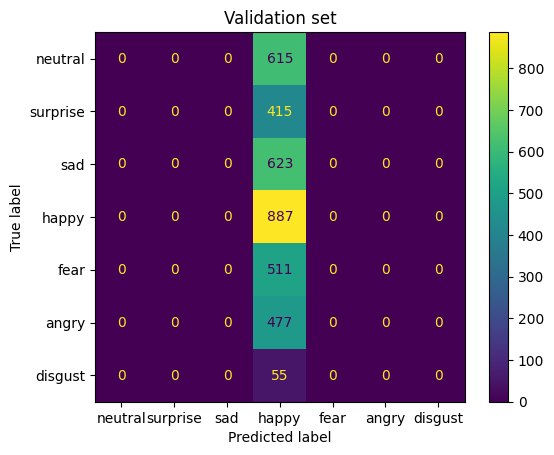

In [42]:
plot_conf_matrix(opt_model_pretrained, X_val_model, y_val, 'Validation set')

## Final Model

In [ ]:
X_complete = np.concat([X_train_model, X_val_model])
y_complete = np.concat([y_train_one_hot, y_val_one_hot])

In [ ]:
opt_model = vgg_model(X_complete, y_complete, labels, drop_rate=0.0, aug_strength='light')

opt_model.summary()

opt_model.compile(
  optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
  loss=tf.keras.losses.CategoricalCrossentropy(),
  metrics=['accuracy'])

history = opt_model.fit(
    X_complete, y_complete,
    epochs=30,
    batch_size=128,
    shuffle = True
)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gray_to_rgb (Lambda)            │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_1 (RandomFlip)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_2 (RandomRotation)    │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_3 (RandomTranslation) │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_light_4 (RandomZoom)        │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 48, 48, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 6, 6, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 3, 3, 512)      │     2,359,80

 Total params: 20,027,975 (76.40 MB)

 Trainable params: 20,027,975 (76.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 39s 128ms/step - accuracy: 0.2580 - loss: 1.8294
Epoch 2/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 34s 136ms/step - accuracy: 0.3573 - loss: 1.6255
Epoch 3/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 37s 144ms/step - accuracy: 0.4252 - loss: 1.4782
Epoch 4/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 36s 143ms/step - accuracy: 0.4555 - loss: 1.3984
Epoch 5/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 37s 145ms/step - accuracy: 0.4898 - loss: 1.3202
Epoch 6/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 42s 150ms/step - accuracy: 0.5175 - loss: 1.2588
Epoch 7/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 39s 153ms/step - accuracy: 0.5408 - loss: 1.2033
Epoch 8/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 39s 154ms/step - accuracy: 0.5597 - loss: 1.1621
Epoch 9/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 40s 149ms/step - accuracy: 0.5727 - loss: 1.1252
Epoch 10/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 38s 149ms/step - accuracy: 0.5863 - loss: 1.0979
Epoch 11/30
253/253 ━━━━━━━━━━━━━━━━━━━━ 36s 142ms/step - accuracy: 0.5958 - loss: 1.0734
Epoch 12/30
253/253

In [ ]:
y_test_pred_one = opt_model.predict(X_test_model)
y_test_pred = np.argmax(y_test_pred_one, axis=1)

113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step


In [ ]:
report = metrics.classification_report(
    y_test, y_test_pred,
    labels=[int(l) for l in labels.keys()],
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).T
report_df = report_df[["precision","recall","f1-score","support"]]
label_map = {str(int(k)): v for k, v in labels.items()}
report_df["label_name"] = report_df.index.map(label_map)
print("Report Results on Testing Dataset:")
print(report_df.to_string())

Report Results on Validation Dataset:
              precision    recall  f1-score      support label_name
4              0.489796  0.740260  0.589528   616.000000    neutral
6              0.726496  0.821256  0.770975   414.000000   surprise
5              0.572482  0.374598  0.452867   622.000000        sad
3              0.866744  0.844244  0.855346   886.000000      happy
2              0.505800  0.425781  0.462354   512.000000       fear
0              0.599119  0.567850  0.583065   479.000000      angry
1              0.677419  0.375000  0.482759    56.000000    disgust
accuracy       0.638215  0.638215  0.638215     0.638215        NaN
macro avg      0.633979  0.592713  0.599556  3585.000000        NaN
weighted avg   0.644459  0.638215  0.631771  3585.000000        NaN


In [ ]:
p, r, f1, _ = metrics.precision_recall_fscore_support(
  y_test, y_test_pred, average="weighted", zero_division=0
)
acc = metrics.accuracy_score(y_test, y_test_pred)
b_acc = metrics.balanced_accuracy_score(y_test, y_test_pred)

print(f'Accuracy: {acc}')
print(f'Balanced Accuracy: {b_acc}')
print(f'Precision: {p}')
print(f'Recall: {r}')
print(f'F1 score: {f1}')

Accuracy: 0.6382147838214783
Balanced Accuracy: 0.5927126541170412
Precision: 0.6444589845674822
Recall: 0.6382147838214783
F1 score: 0.6317714937082429


113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step


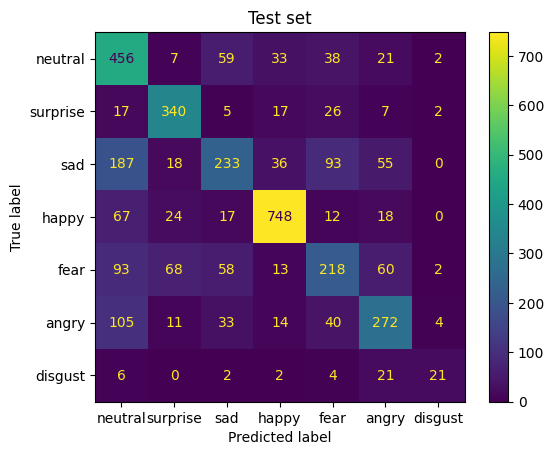

In [ ]:
plot_conf_matrix(opt_model, X_test_model, y_test, 'Test set')

113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


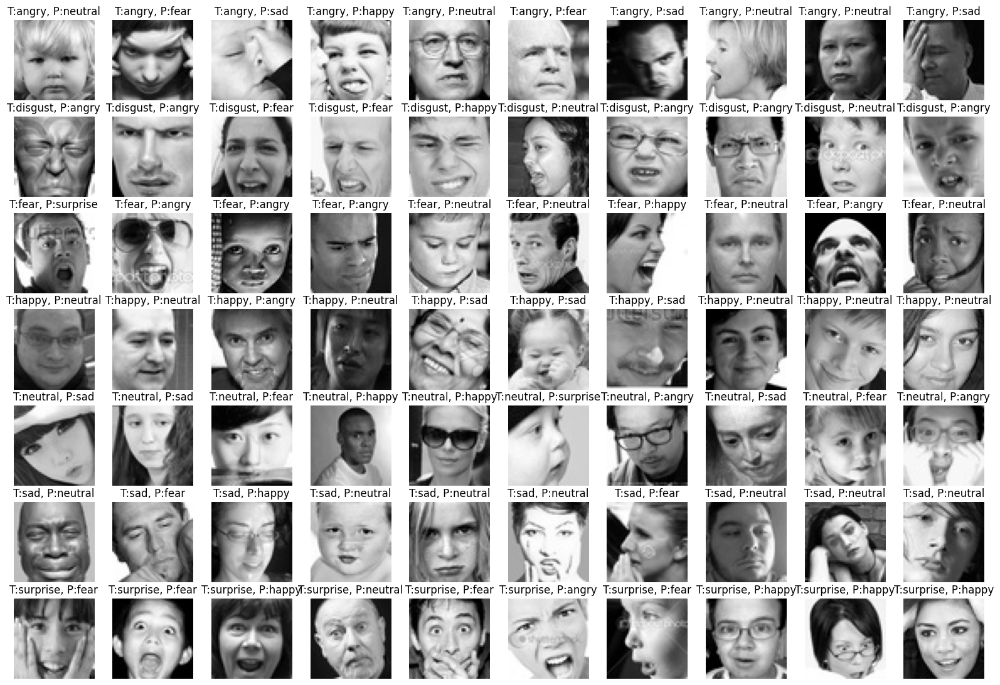

In [ ]:
plot_error_predicted(opt_model, X_test_model, y_test, 'Test set', 10)